In [29]:
# CELL 1
import os
from pandas.core.common import random_state
os.environ["OMP_NUM_THREADS"] = "3"
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
seed = 42
np.random.seed(42)
sklearn.utils.check_random_state(seed)
random.seed(42)

#from pyexpat import features
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
#from imblearn.combine import SMOTEENN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import RFE
import matplotlib.cm as cm
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.decomposition import PCA
import shap
from sklearn.model_selection import GridSearchCV
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from sklearn.metrics import homogeneity_score
from sklearn.pipeline import Pipeline

from sklearnex import patch_sklearn, config_context
patch_sklearn()

from sklearnex.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
#from imblearn.combine import SMOTEENN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearnex.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearnex.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import RFE
import matplotlib.cm as cm
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearnex.decomposition import PCA
import shap
from shap import summary_plot
from sklearn.model_selection import GridSearchCV
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from sklearn.metrics import homogeneity_score
from sklearn.pipeline import Pipeline

import warnings


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


Data Preparation >> Data Wrangling:

ORIGINAL DATASET DOWNLOADED FROM: https://www.kaggle.com/datasets/rabieelkharoua/alzheimers-disease-dataset

In [30]:
# CELL 2
# Data wrangling
alzheimers_original_df = pd.read_csv('alzheimers_disease_data.csv')

count = 0
for column in alzheimers_original_df:
    count += 1
print(f"Total number of columns in dataset before data wrangling is {count}\n")


Total number of columns in dataset before data wrangling is 35



In [31]:
# CELL 3
# More Data Wrangling
# compute descriptive statistics:
print(# calculate mean, standard deviation, min and other quantiles
      f"\n\n\nSummary statistics of dataset before wrangling:\n{alzheimers_original_df.describe()}"
      # find whether there are missing values
      f"\n\n\n{alzheimers_original_df.info()}"
      # find out datatypes
      f"\n\n\nData types of all columns in the dataset before wrangling:\n{alzheimers_original_df.dtypes}")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [32]:
# CELL 4
# More Data Wrangling

# check for duplicate data points -- out of the 2149 data entries, of which non have missing values, are all 2149 values original, or are there duplicates?
alzheimers_original_df.duplicated()


0       False
1       False
2       False
3       False
4       False
        ...  
2144    False
2145    False
2146    False
2147    False
2148    False
Length: 2149, dtype: bool

In [33]:
# CELL 5
# More Data Wrangling

# drop columns that are not needed for analysis; i.e. PatientID and DoctorInCharge
alzheimers_df = alzheimers_original_df.drop(['PatientID', 'DoctorInCharge'], axis=1)
alzheimers_df.head() # define a new variable for the altered dataset to avoid altering the original, as we must "keep a record of all data transformations" performed.

# compute descriptive statistics: calculate mean, standard deviation, min and other quantiles for final dataset
print(f"\n\n\nSummary statistics of dataset after wrangling:\n{alzheimers_df.describe()}")
#a = pd.DataFrame(alzheimers_df.describe())
#a.to_excel("descriptive statistics.xlsx")





Summary statistics of dataset after wrangling:
               Age       Gender    Ethnicity  EducationLevel          BMI  \
count  2149.000000  2149.000000  2149.000000     2149.000000  2149.000000   
mean     74.908795     0.506282     0.697534        1.286645    27.655697   
std       8.990221     0.500077     0.996128        0.904527     7.217438   
min      60.000000     0.000000     0.000000        0.000000    15.008851   
25%      67.000000     0.000000     0.000000        1.000000    21.611408   
50%      75.000000     1.000000     0.000000        1.000000    27.823924   
75%      83.000000     1.000000     1.000000        2.000000    33.869778   
max      90.000000     1.000000     3.000000        3.000000    39.992767   

           Smoking  AlcoholConsumption  PhysicalActivity  DietQuality  \
count  2149.000000         2149.000000       2149.000000  2149.000000   
mean      0.288506           10.039442          4.920202     4.993138   
std       0.453173            5.75791

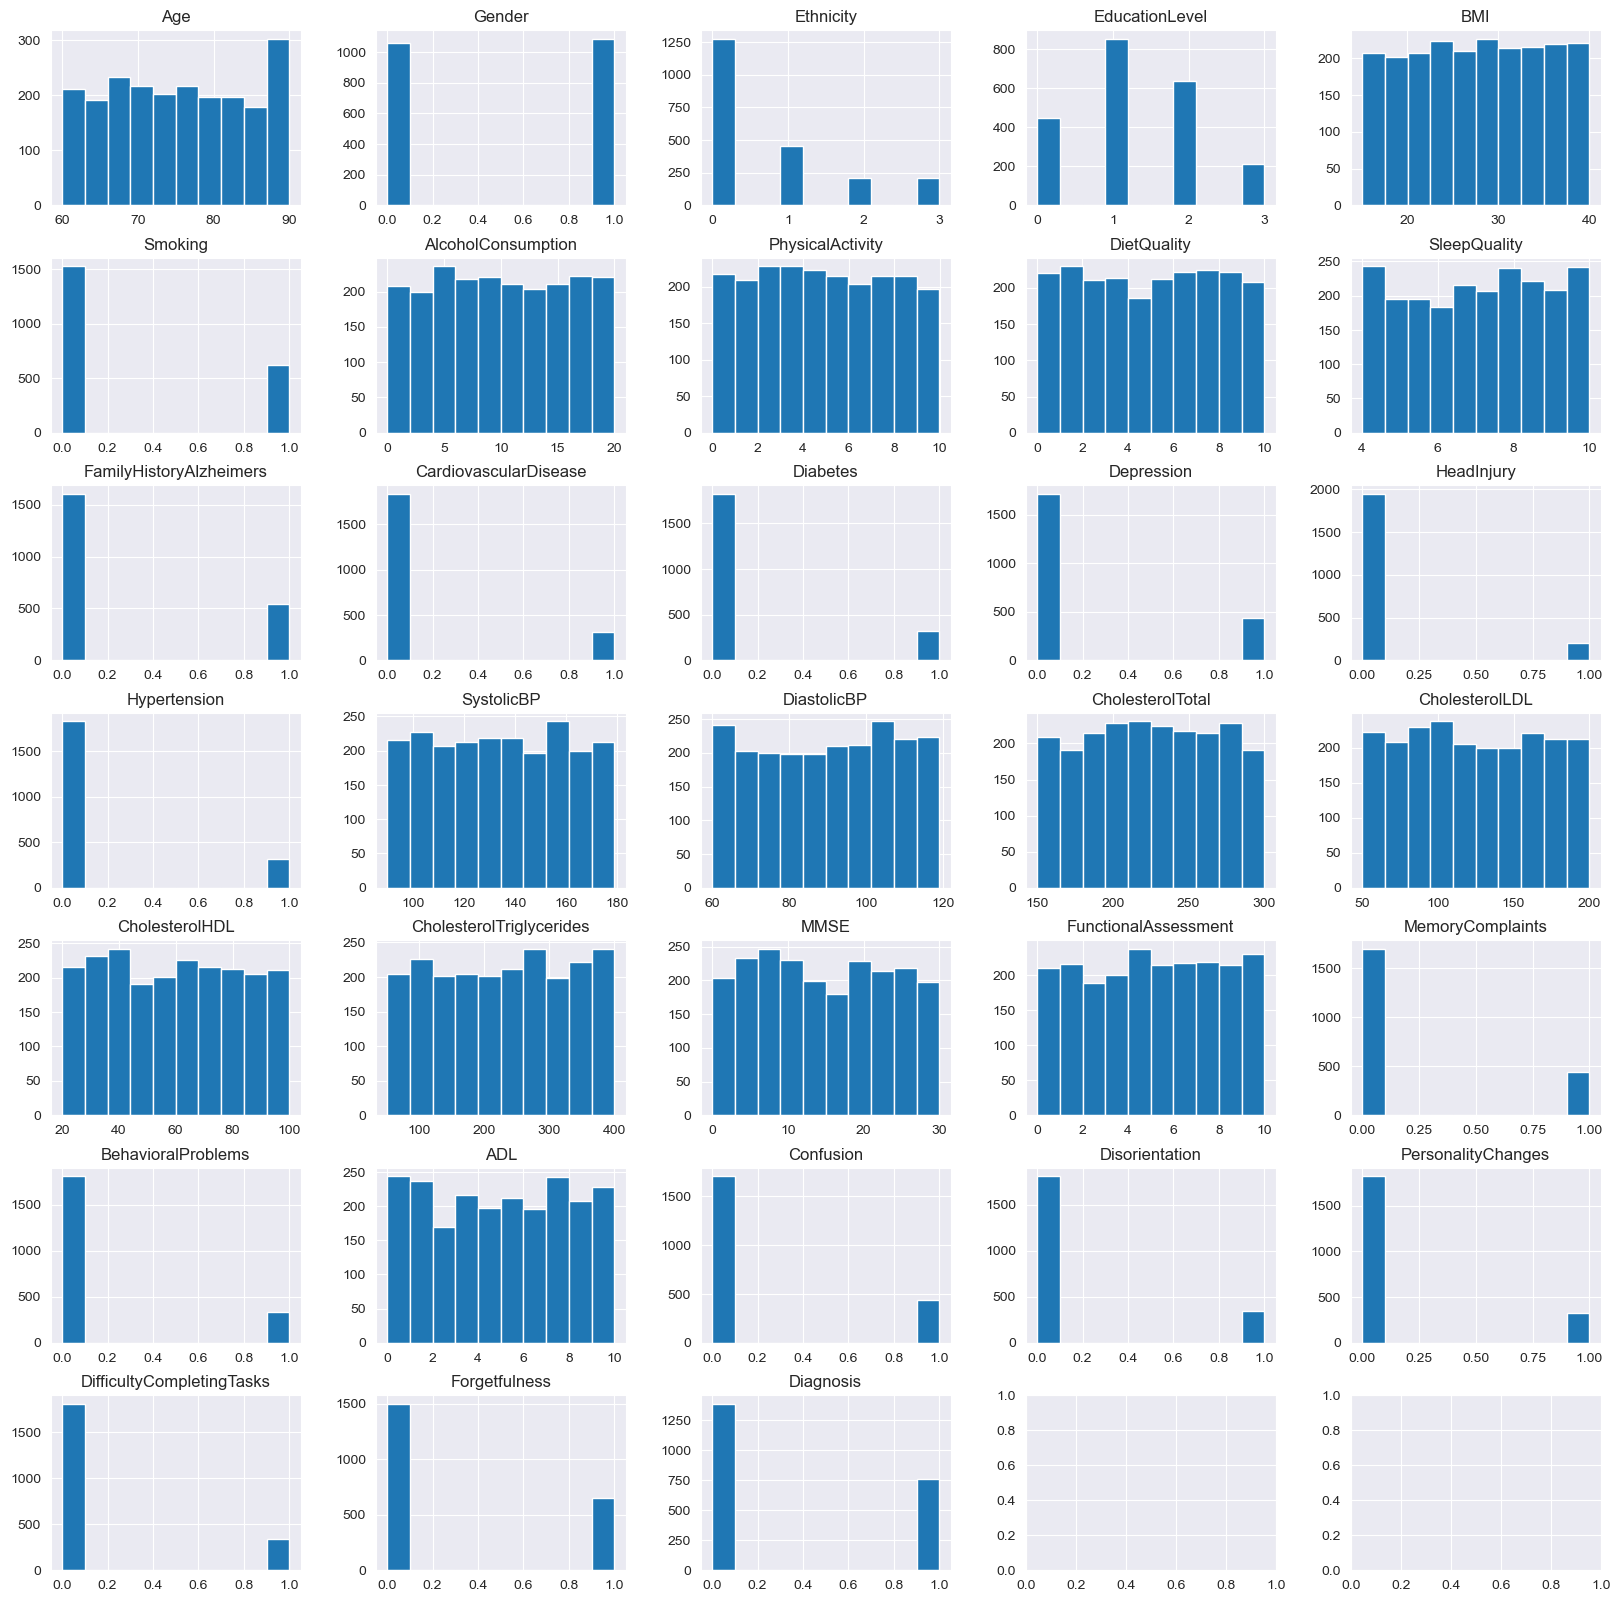

In [34]:
# CELL 6
# More Data Wrangling

# Look at the distributions with a histogram for each variable. Study the distributions of variables to determine whether it might be worth transforming them.

# Visualization of raw data for comparing distribution of data samples across features (no separation between positive and negative diagnosis)
alzheimers_numerical_df =alzheimers_df.select_dtypes(include='number') # select numeric columns only

numCols = alzheimers_numerical_df.shape[1] # Get the number of columns

fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_numerical_df.hist(column=alzheimers_numerical_df.columns[i], bins=10, ax=axis)
            i = i + 1

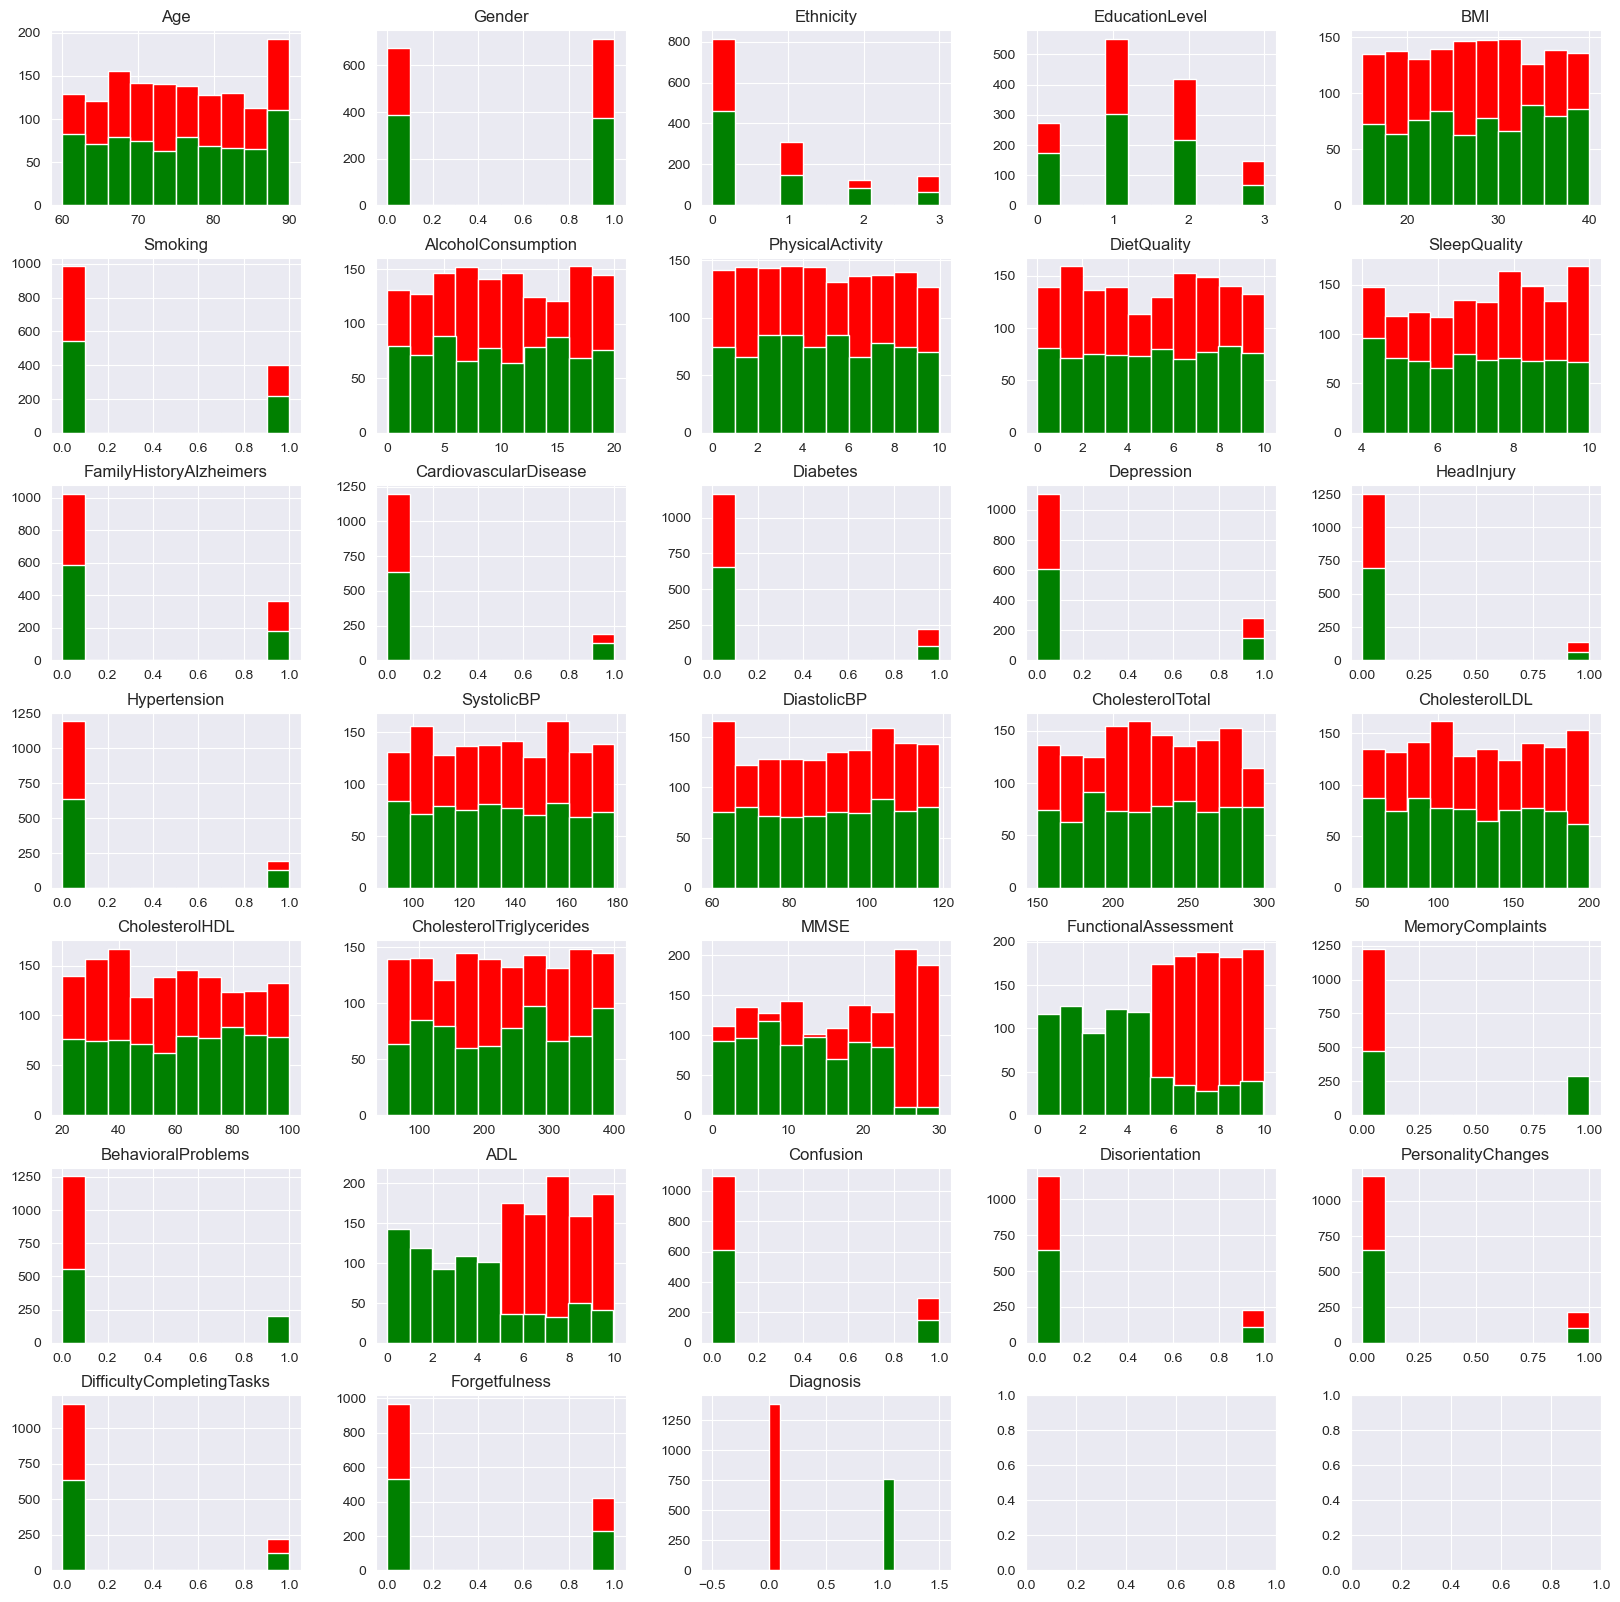

In [35]:
# CELL 7
# More Data Wrangling

# visualization of the entire dataset AFTER HAVING REMOVED UNNECESSARY COLUMNS, for comparing distribution of data samples BETWEEN POSITIVE AND NEGATIVE DIAGNOSIS across features
alzheimers_numerical_df = alzheimers_df.select_dtypes(include='number')  # select numeric columns only
alzheimers_negative_df = alzheimers_numerical_df[alzheimers_df['Diagnosis'] == 0]
alzheimers_positive_df = alzheimers_numerical_df[alzheimers_df['Diagnosis'] == 1]

numCols = alzheimers_numerical_df.shape[1]  # get number of columns
fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')
            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')
            i = i + 1

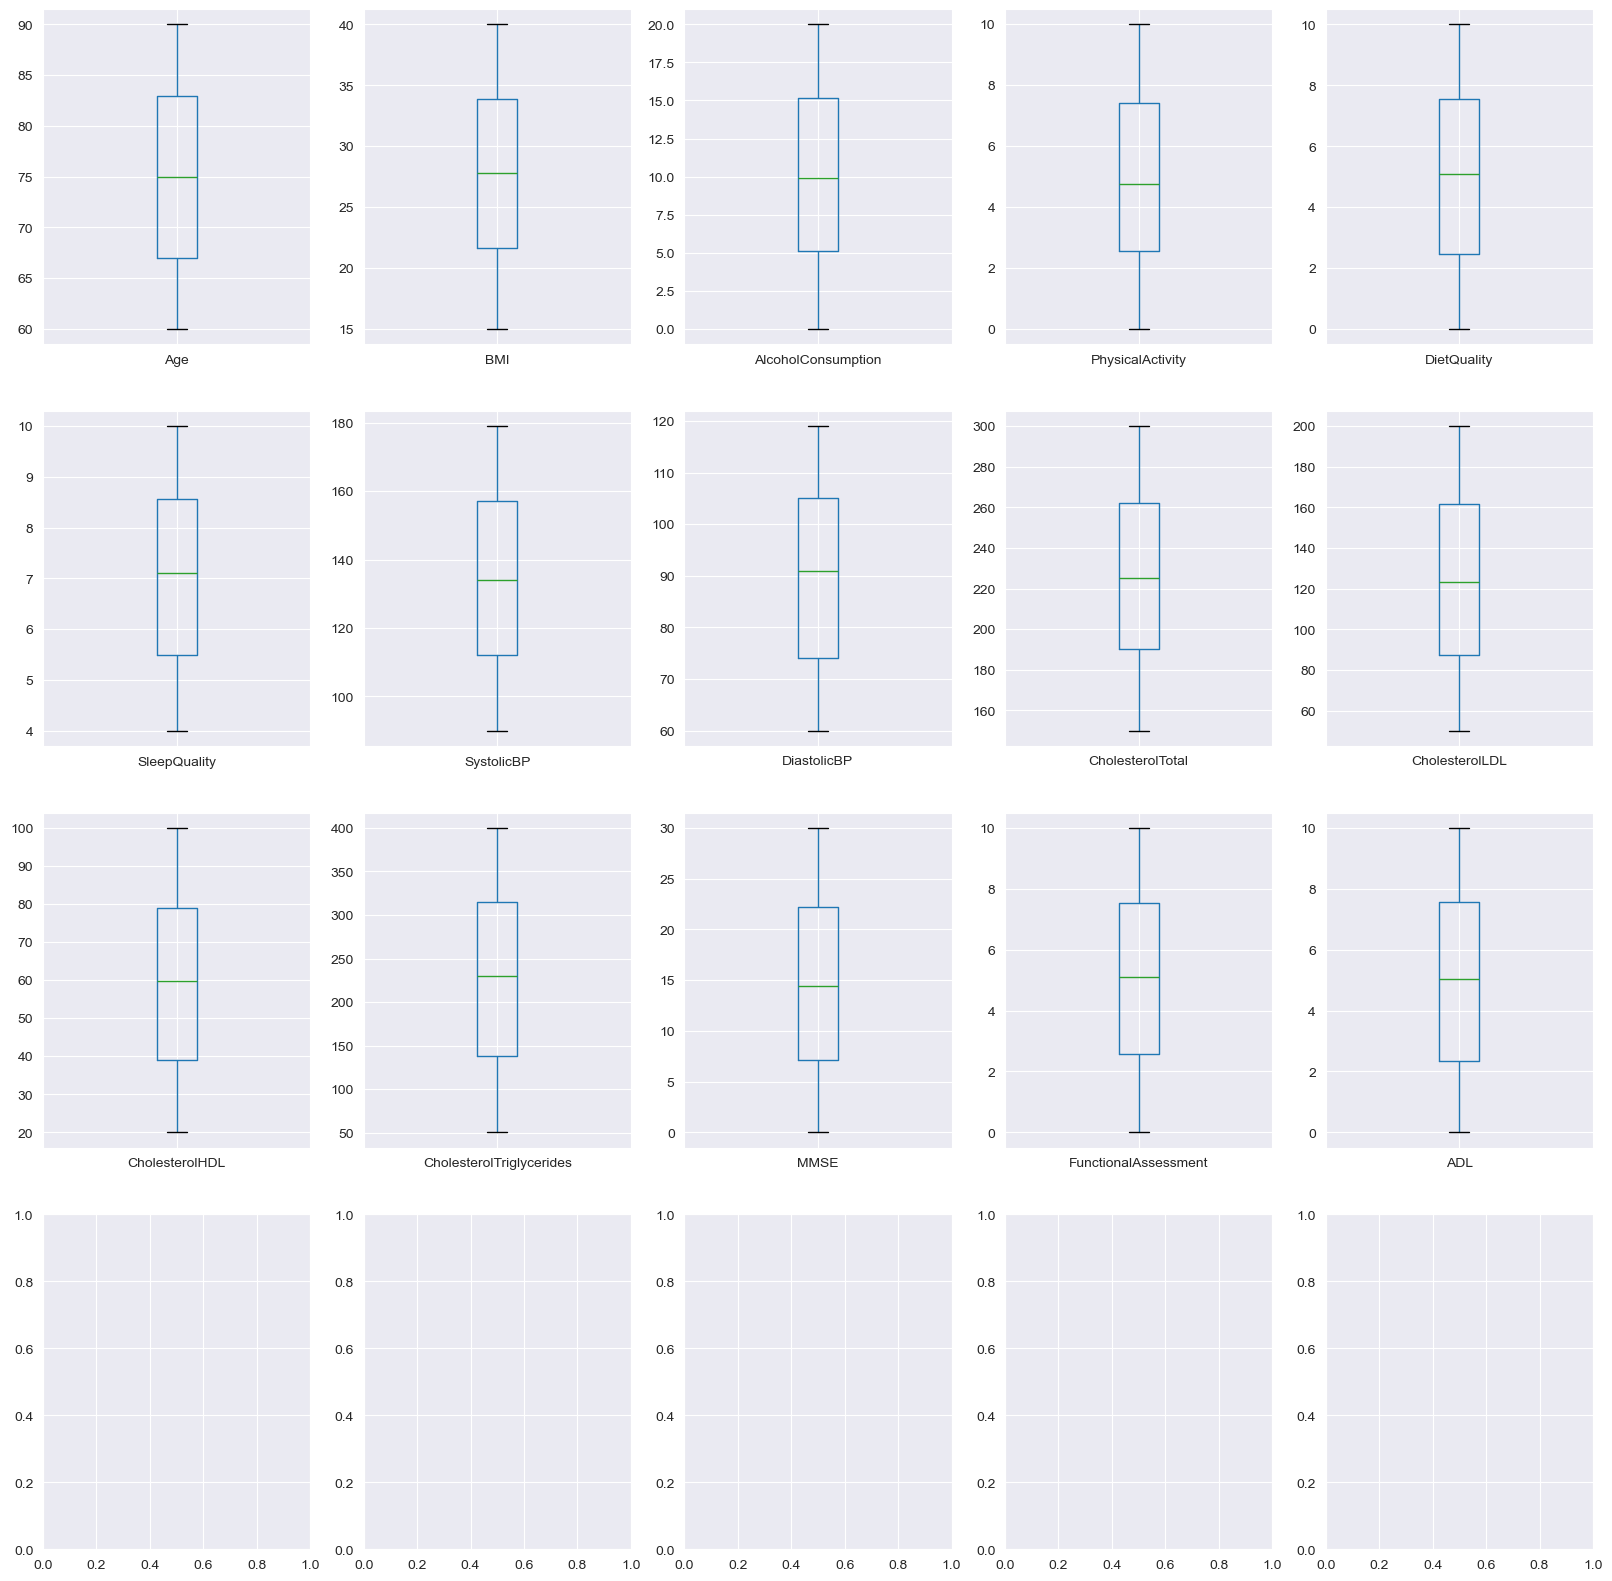

In [36]:
# CELL 8
# Test for outliers and remove them if needed. From these box plots, which serve as a graphical approach to outlier detection, it can be seen none of the features in my dataset have any outliers. Thus, there is no need to implement code for removing outliers.

# Test for outliers using a graphical approach (box plot and/or scatterplot. I have chosen to use box plots for this purpose).

alzheimers_drop_categorical_df = alzheimers_df.drop(['Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness', 'MemoryComplaints', 'BehavioralProblems', 'FamilyHistoryAlzheimers','CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'Ethnicity', 'EducationLevel', 'Gender', 'Smoking', 'Diagnosis'], axis=1)

numCols = alzheimers_drop_categorical_df.shape[1]

fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_drop_categorical_df.boxplot(column=alzheimers_drop_categorical_df.columns[i], ax=axis)
            i = i + 1


In [37]:
# CELL 9
# More Data Wrangling
# It is clear that the dataset is unbalanced from the "Diagnosis" feature plot. Let's conduct some further testing.

negative = (alzheimers_df['Diagnosis'] == 0).sum()
positive = (alzheimers_df['Diagnosis'] == 1).sum()

print(f"Negative count: {negative}\nPositive count: {positive}")
# from alzheimers_original_df.info(), we know RangeIndex: 2149 entries, 0 to 2148. So:
print(f"Percentage of patients/entries in dataset were diagnosis is negative: {(negative / 2149)*100}\n Percentage of patients/entries in dataset were diagnosis is positive: {(positive / 2149)*100}")

Negative count: 1389
Positive count: 760
Percentage of patients/entries in dataset were diagnosis is negative: 64.63471382038158
 Percentage of patients/entries in dataset were diagnosis is positive: 35.36528617961843


In [38]:
# CELL 10
# More Data Wrangling

# From the above we can see that the dataset is moderately unbalanced. We will consider resampling into a balanced dataset if the performance of the models is poor. See cells below. The performance of RandomForest was originally quite poor in the first iteration of the DS Process, with the model clearly overfitting. Resample data to make the dataset balanced. Perform train-test and train-validation split, as resampling must be done after splitting the dataset into train, validation and testing subsets.
X = alzheimers_df.drop(columns=['Diagnosis'])
y = alzheimers_df['Diagnosis']

# train-test split and validation split FOR THE CLASSIFICATION MODELS (not needed for the clustering model)
X_train_temp, X_test, y_train_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_temp, y_train_temp, test_size=0.1, random_state=42)
print(f"Size of training subset: {X_train.shape[0]}, which makes up {(X_train.shape[0]/2149)*100} of the total dataset. \nSize of validation subset: {X_val.shape[0]}, which makes up {(X_val.shape[0]/2149)*100}\nSize of testing subset: {X_test.shape[0]}, which makes up {(X_test.shape[0]/2149)*100}\n\n\n")

# Dataset resampling -- removing samples from the majority class FOR THE CLASSIFICATION MODELS (not needed for the clustering model)
# only to be done for the training subset (https://medium.com/data-science-at-microsoft/five-mistakes-to-avoid-when-modeling-with-imbalanced-datasets-d58a8c09929c)

rus_under = RandomUnderSampler(random_state=42)
X_under_sampled, y_under_sampled = rus_under.fit_resample(X_train, y_train)
print(f"Size of UNDERSAMPLED training subset: {X_under_sampled.shape[0]}"
      f"Size of y_over_sampled: {y_under_sampled.shape[0]}"
      f"Columns in X_over_sampled (what features does it contain?): {X_under_sampled.columns}\n")

rus_over = RandomOverSampler(random_state=42)
X_over_sampled, y_over_sampled = rus_over.fit_resample(X_train, y_train)
print(f"Size of OVERSAMPLED training subset: {X_over_sampled.shape[0]}"
      f"Size of y_over_sampled: {y_over_sampled.shape[0]}"
      f"Columns in X_over_sampled (what features does it contain?): {X_over_sampled.columns}\n")

# FIRST ANALYTICAL QUESTION:
# now that data has been resampled, we select the features we need to answer our first analytical question, which will use RandomForest
X_under_sampled_features_q1 = X_under_sampled[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity',
                   'DietQuality', 'SleepQuality']]
X_over_sampled_features_q1 = X_over_sampled[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity',
                   'DietQuality', 'SleepQuality']]
# alternative for when not resampling
X_features_q1 = X_train[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity',
                   'DietQuality', 'SleepQuality']]
X_val_q1 = X_val[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity',
                   'DietQuality', 'SleepQuality']]
X_test_q1 = X_test[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity',
                   'DietQuality', 'SleepQuality']]


# SECOND ANALYTICAL QUESTION:
# now that data has been resampled, we select the features we need to answer our second analytical question, which will use LogisticRegression
X_under_sampled_features_q2 = X_under_sampled[['BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]
X_over_sampled_features_q2 = X_over_sampled[['BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]
# alternative for when not resampling
X_features_q2 = X_train[['BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]
X_val_q2 = X_val[['BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]
X_test_q2 = X_test[['BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]


# THIRD ANALYTICAL QUESTION, for which we do not need train-test split, train-validation split nor resampling to make the dataset balanced:
# we select the features we need to answer our third analytical question, which will use KMeans clustering
# Even though dataset does not classify 'MemoryComplaints' and 'BehavioralProblems' as symptoms, but as Cognitive and Functional Assessments, we do. Hence, symptoms, whether resampled or not = ['MemoryComplaints', 'Confusion', 'Disorientation', 'PersonalityChanges', 'BehavioralProblems', 'DifficultyCompletingTasks', 'Forgetfulness']

# IMPORTANT: We are studying the relationship between atypical symptoms and clinical, environmental and lifestyle factors IN PATIENTS SUFFERING FROM THE DISEASE (i.e. data points where 'Diagnosis'==1). As such, we must restrict the data used only to those data points where diagnosis is positive.
# Additionally, "Another point to consider is that a train test split is not required for this model as it is unsupervised learning with no labels to test." (https://www.geeksforgeeks.org/machine-learning/k-means-clustering-on-the-handwritten-digits-data-using-scikit-learn-in-python/). There is also no need to resample data to balance the dataset, as we do not aim to predict labels.
alzheimers_positive_q3_df = alzheimers_df[alzheimers_df['Diagnosis'] == 1]
X_features_q3 = alzheimers_positive_q3_df.drop(columns=['Diagnosis'], inplace=False)
print("Q3 features used in training the K-means Clustering model\n", X_features_q3.columns.tolist())
X_symptoms_q3 = X_features_q3[['Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness', 'MemoryComplaints', 'BehavioralProblems']]
X_factors_identified_q3 = X_features_q3[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides']]

print(f"Size of alzheimers_positive_q3_df: {alzheimers_positive_q3_df.shape[0]}\nalzheimers_positive_q3_df.head(10):\n{alzheimers_positive_q3_df.head(10)}\n\n\n,"
      f"Size of X_features_q3: {X_features_q3.shape[0]}\nX_features_q3.head(10):\n{X_features_q3.head(10)}\n\n\n,"
      f"Size of X_symptoms_q3: {X_symptoms_q3.shape[0]}\nX_symptoms_q3.head(10):\n{X_symptoms_q3.head(10)}\n\n\n,"
      f"Size of X_factors_identified_q3: {X_factors_identified_q3.shape[0]}\nX_factors_identified_q3.head(10):\n{X_factors_identified_q3.head(10)}\n\n\n")


# only to be used for estimating symptom prevalence, NEVER to be used in training the K-Means clustering model for answering the third analytical question:
X_symptoms_with_diagnosis_q3 = alzheimers_df[['Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness', 'MemoryComplaints', 'BehavioralProblems', 'Diagnosis']]
X_factors_identified_with_diagnosis_q3= alzheimers_df[['EducationLevel', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL','CholesterolHDL', 'CholesterolTriglycerides', 'Diagnosis']]


Size of training subset: 1547, which makes up 71.9869706840391 of the total dataset. 
Size of validation subset: 172, which makes up 8.003722661703119
Size of testing subset: 430, which makes up 20.009306654257795



Size of UNDERSAMPLED training subset: 1108Size of y_over_sampled: 1108Columns in X_over_sampled (what features does it contain?): Index(['Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI', 'Smoking',
       'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality',
       'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes',
       'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP', 'DiastolicBP',
       'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness'],
      dtype='object')

Size of OVERSAMPLED traini

In [39]:
# CELL 11
# define a new variable for the altered dataset to avoid altering the original, as we must "keep a record of all data transformations" performed, but also, because for analysis we still aim to use "alzheimers_df", with all relevant categorical columns still present, and so we double-check that the columns in "alzheimers_df" have not been altered by the code above before proceeding.

print(#f"Check alzheimers_df:\n {alzheimers_df.columns}\n {alzheimers_df.head()}\n"
      #f"Check X:\n {X.columns}\n {X.head()}\n"
      #f"Check y:\n {X.columns}\n {X.head()}\n"
      #f"Check X shape:\n {X.shape[0]}\n"
      #f"Check y shape: \n {y.shape[0]}\n"
      f"Check X_resampled shape: \n {X_under_sampled.shape[0]}\n"
      f"Check y_resampled shape: \n {y_under_sampled.shape[0]}\n"
      f"Check X_resampled shape: \n {X_over_sampled.shape[0]}\n"
      f"Check y_resampled shape: \n {y_over_sampled.shape[0]}\n"
      #f"Check X_resampled_features_q1 shape: \n {X_resampled_features_q1.shape[0]}\n"
      #f"Check elements contained by X_resampled: \n {X_resampled.values}\n"
      f"Check elements contained by X_resampled HEAD: \n {X_under_sampled.head()}\n"
      f"Check elements contained by X_resampled HEAD: \n {X_over_sampled.head()}\n"
      #f"Check elements contained by y_resampled: \n {y_resampled.values}\n"
      f"Check UNIQUE elements contained by y_resampled: \n {y_under_sampled.unique()}\n"
      f"Check dtype of y_resampled: \n {y_under_sampled.dtype}\n"
      f"Check UNIQUE elements contained by y_resampled: \n {y_over_sampled.unique()}\n"
      f"Check dtype of y_resampled: \n {y_over_sampled.dtype}\n")


Check X_resampled shape: 
 1108
Check y_resampled shape: 
 1108
Check X_resampled shape: 
 1986
Check y_resampled shape: 
 1986
Check elements contained by X_resampled HEAD: 
       Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
1495   90       1          3               0  24.332593        1   
1027   76       0          0               1  28.229196        0   
908    73       0          0               3  27.189229        0   
825    81       0          0               1  29.071527        0   
418    80       0          0               0  32.977412        0   

      AlcoholConsumption  PhysicalActivity  DietQuality  SleepQuality  ...  \
1495           12.058027          5.982201     9.317233      4.205879  ...   
1027            9.092742          5.223628     3.253398      9.892413  ...   
908            16.285787          8.590148     8.564807      6.679793  ...   
825             9.702742          5.115925     0.878435      4.896331  ...   
418             6.133179 

Negative count AFTER UNDERSAMPLING: 554
Positive count AFTER UNDERSAMPLIING: 554
Percentage of patients/entries in dataset were diagnosis is negative AFTER UNDERSAMPLING: 50.0
 Percentage of patients/entries in dataset were diagnosis is positive AFTER UNDERSAMPLING: 50.0


"fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))\ni = 0\nfor axisCols in axisRows:\n    for axis in axisCols:\n        if (i < numCols):\n            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')\n            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')\n            i = i + 1"

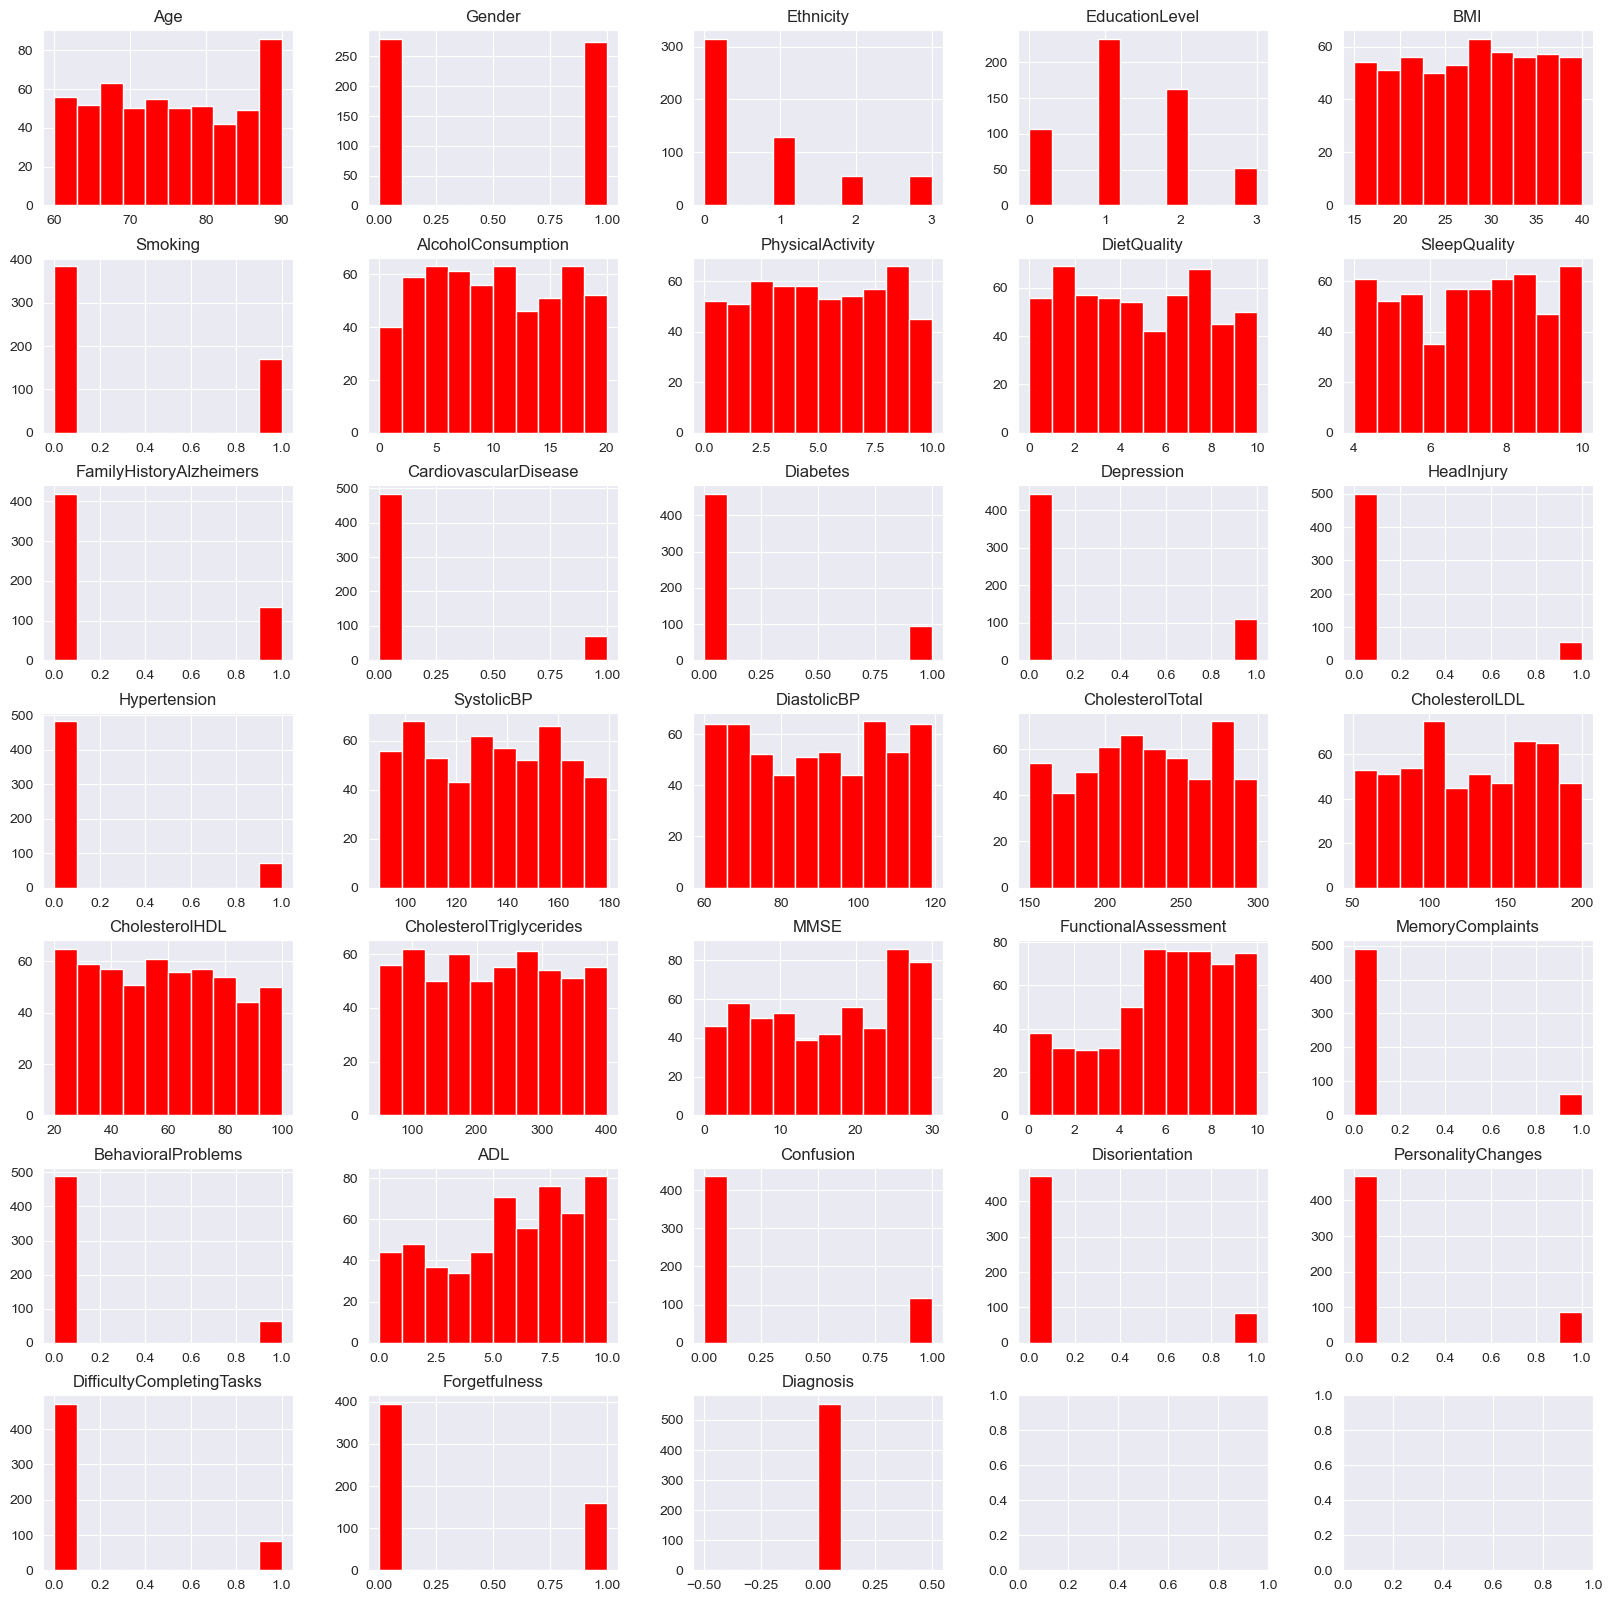

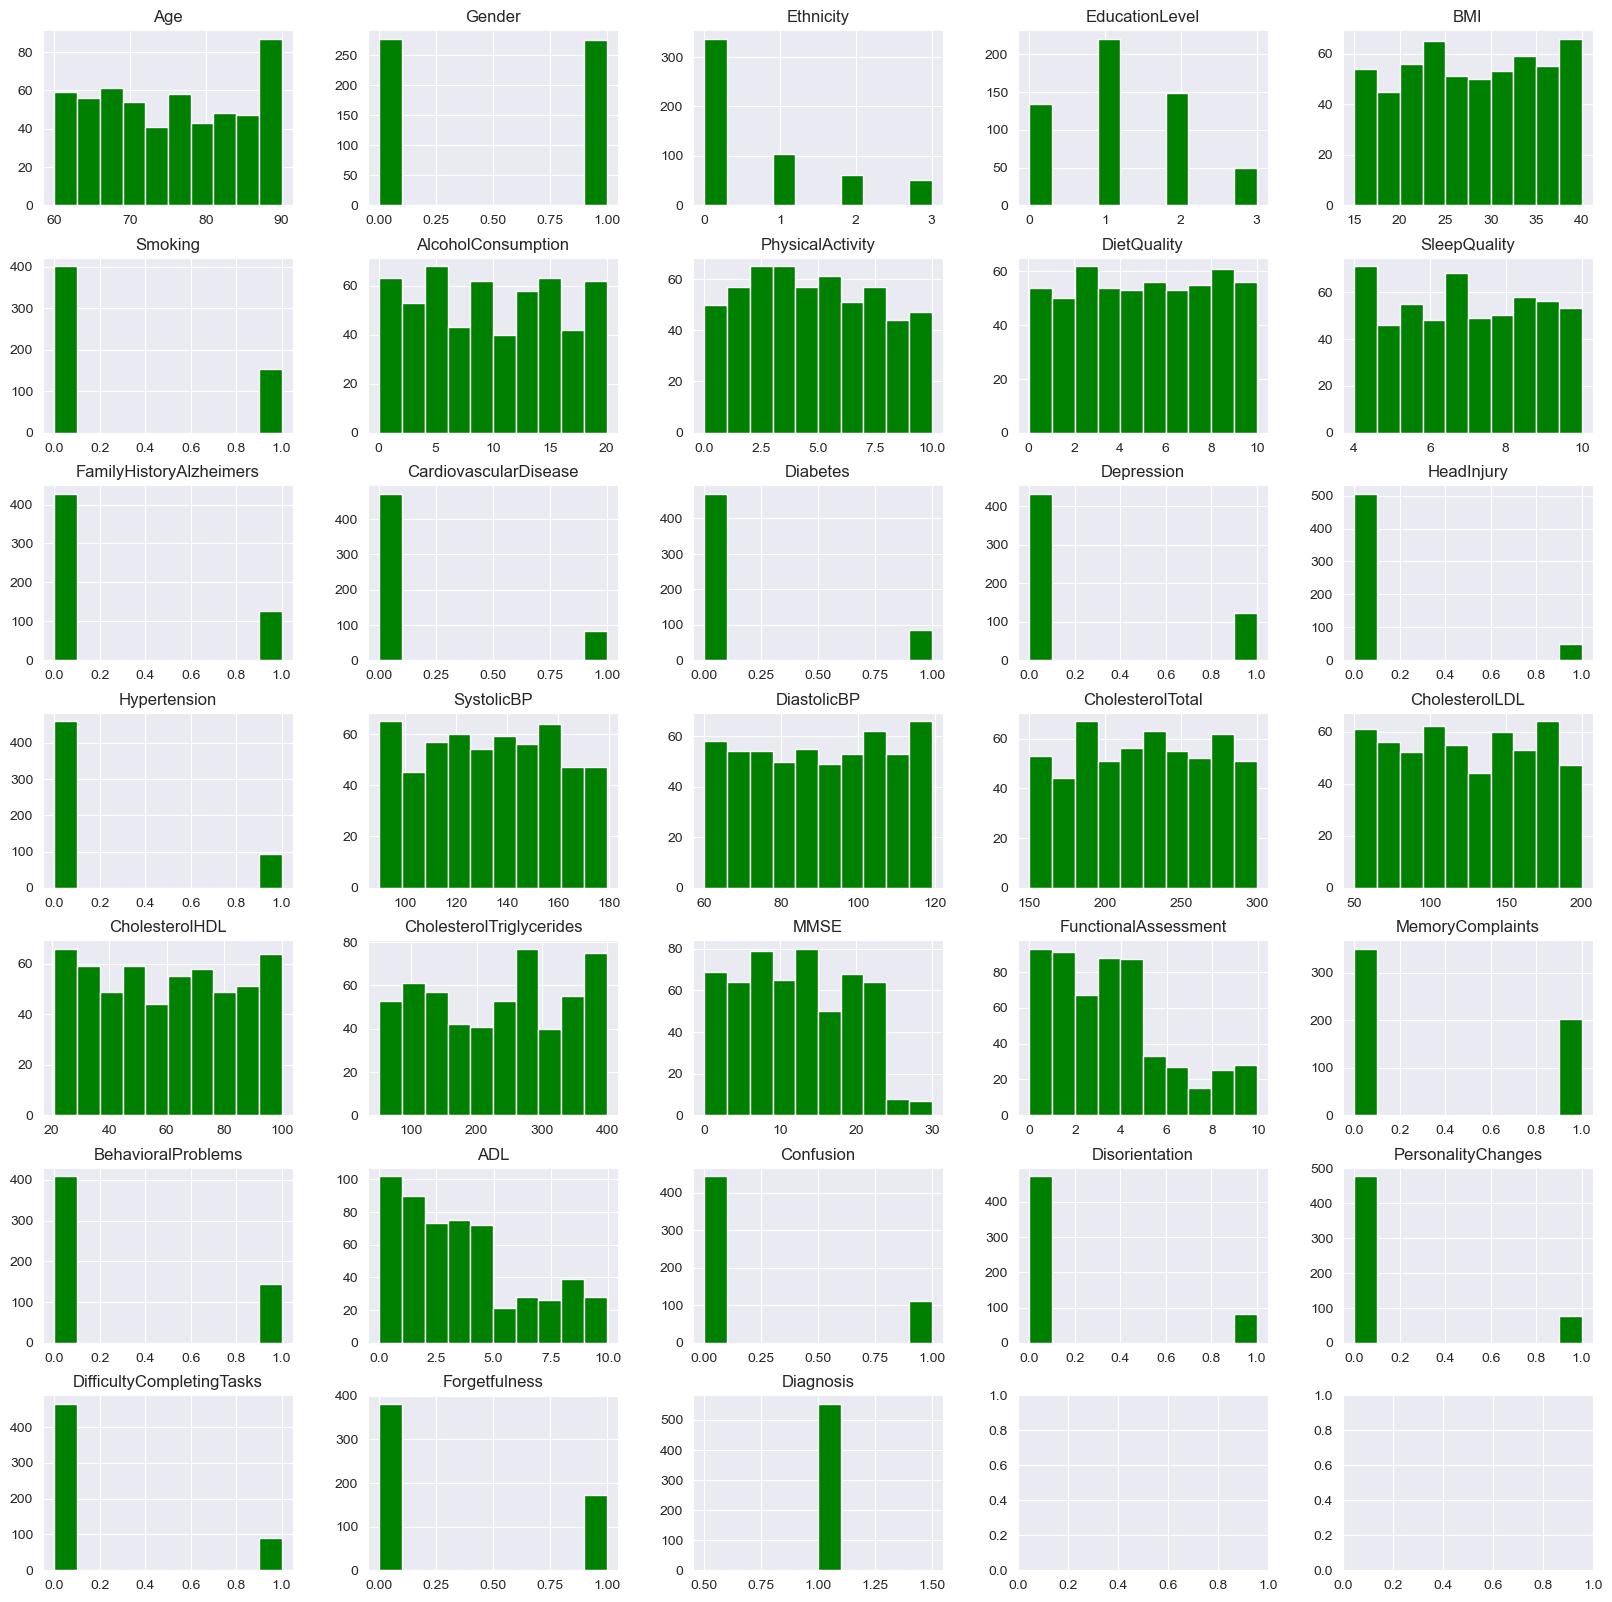

In [40]:
# CELL 12
# More Data Wrangling

# visualization of TRAINING (UNDERSAMPLED) dataset AFTER HAVING REMOVED UNNECESSARY COLUMNS, for comparing distribution of data samples BETWEEN POSITIVE AND NEGATIVE DIAGNOSIS across features.
# The dataset has already been split into train, validation and test subsets and the training dataset resampled. alzheimers_temp_concat_resampled_df is only a temporary variable that will NOT be used. In alzheimers_temp_concat_resampled_df, X_resampled and y_resampled are only merged for visualization purposes, so we can visually analyse and verify that the training dataset has indeed been resampled and is not balanced.
alzheimers_temp_concat_resampled_df = pd.concat([X_under_sampled, y_under_sampled], axis=1)
alzheimers_numerical_df = alzheimers_temp_concat_resampled_df.select_dtypes(include='number')  # select numeric columns only
alzheimers_negative_df = alzheimers_numerical_df[alzheimers_temp_concat_resampled_df['Diagnosis'] == 0]
alzheimers_positive_df = alzheimers_numerical_df[alzheimers_temp_concat_resampled_df['Diagnosis'] == 1]
negative_resampled = (alzheimers_temp_concat_resampled_df['Diagnosis'] == 0).sum()
positive_resampled = (alzheimers_temp_concat_resampled_df['Diagnosis'] == 1).sum()

print(f"Negative count AFTER UNDERSAMPLING: {negative_resampled}\nPositive count AFTER UNDERSAMPLIING: {positive_resampled}")
# from X_under_sampled.shape[0], we know 1108 entries. So:
print(f"Percentage of patients/entries in dataset were diagnosis is negative AFTER UNDERSAMPLING: {(negative_resampled / 1108)*100}\n Percentage of patients/entries in dataset were diagnosis is positive AFTER UNDERSAMPLING: {(positive_resampled / 1108)*100}")

numCols = alzheimers_numerical_df.shape[1]  # get number of columns
fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')
            i = i + 1


fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')
            i = i + 1

'''fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')
            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')
            i = i + 1'''

Negative count AFTER OVERSAMPLING: 993
Positive count AFTER OVERSAMPLIING: 993
Percentage of patients/entries in dataset were diagnosis is negative AFTER OVERSAMPLING: 46.207538389948816
 Percentage of patients/entries in dataset were diagnosis is positive AFTER OVERSAMPLING: 46.207538389948816


"fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))\ni = 0\nfor axisCols in axisRows:\n    for axis in axisCols:\n        if (i < numCols):\n            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')\n            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')\n            i = i + 1"

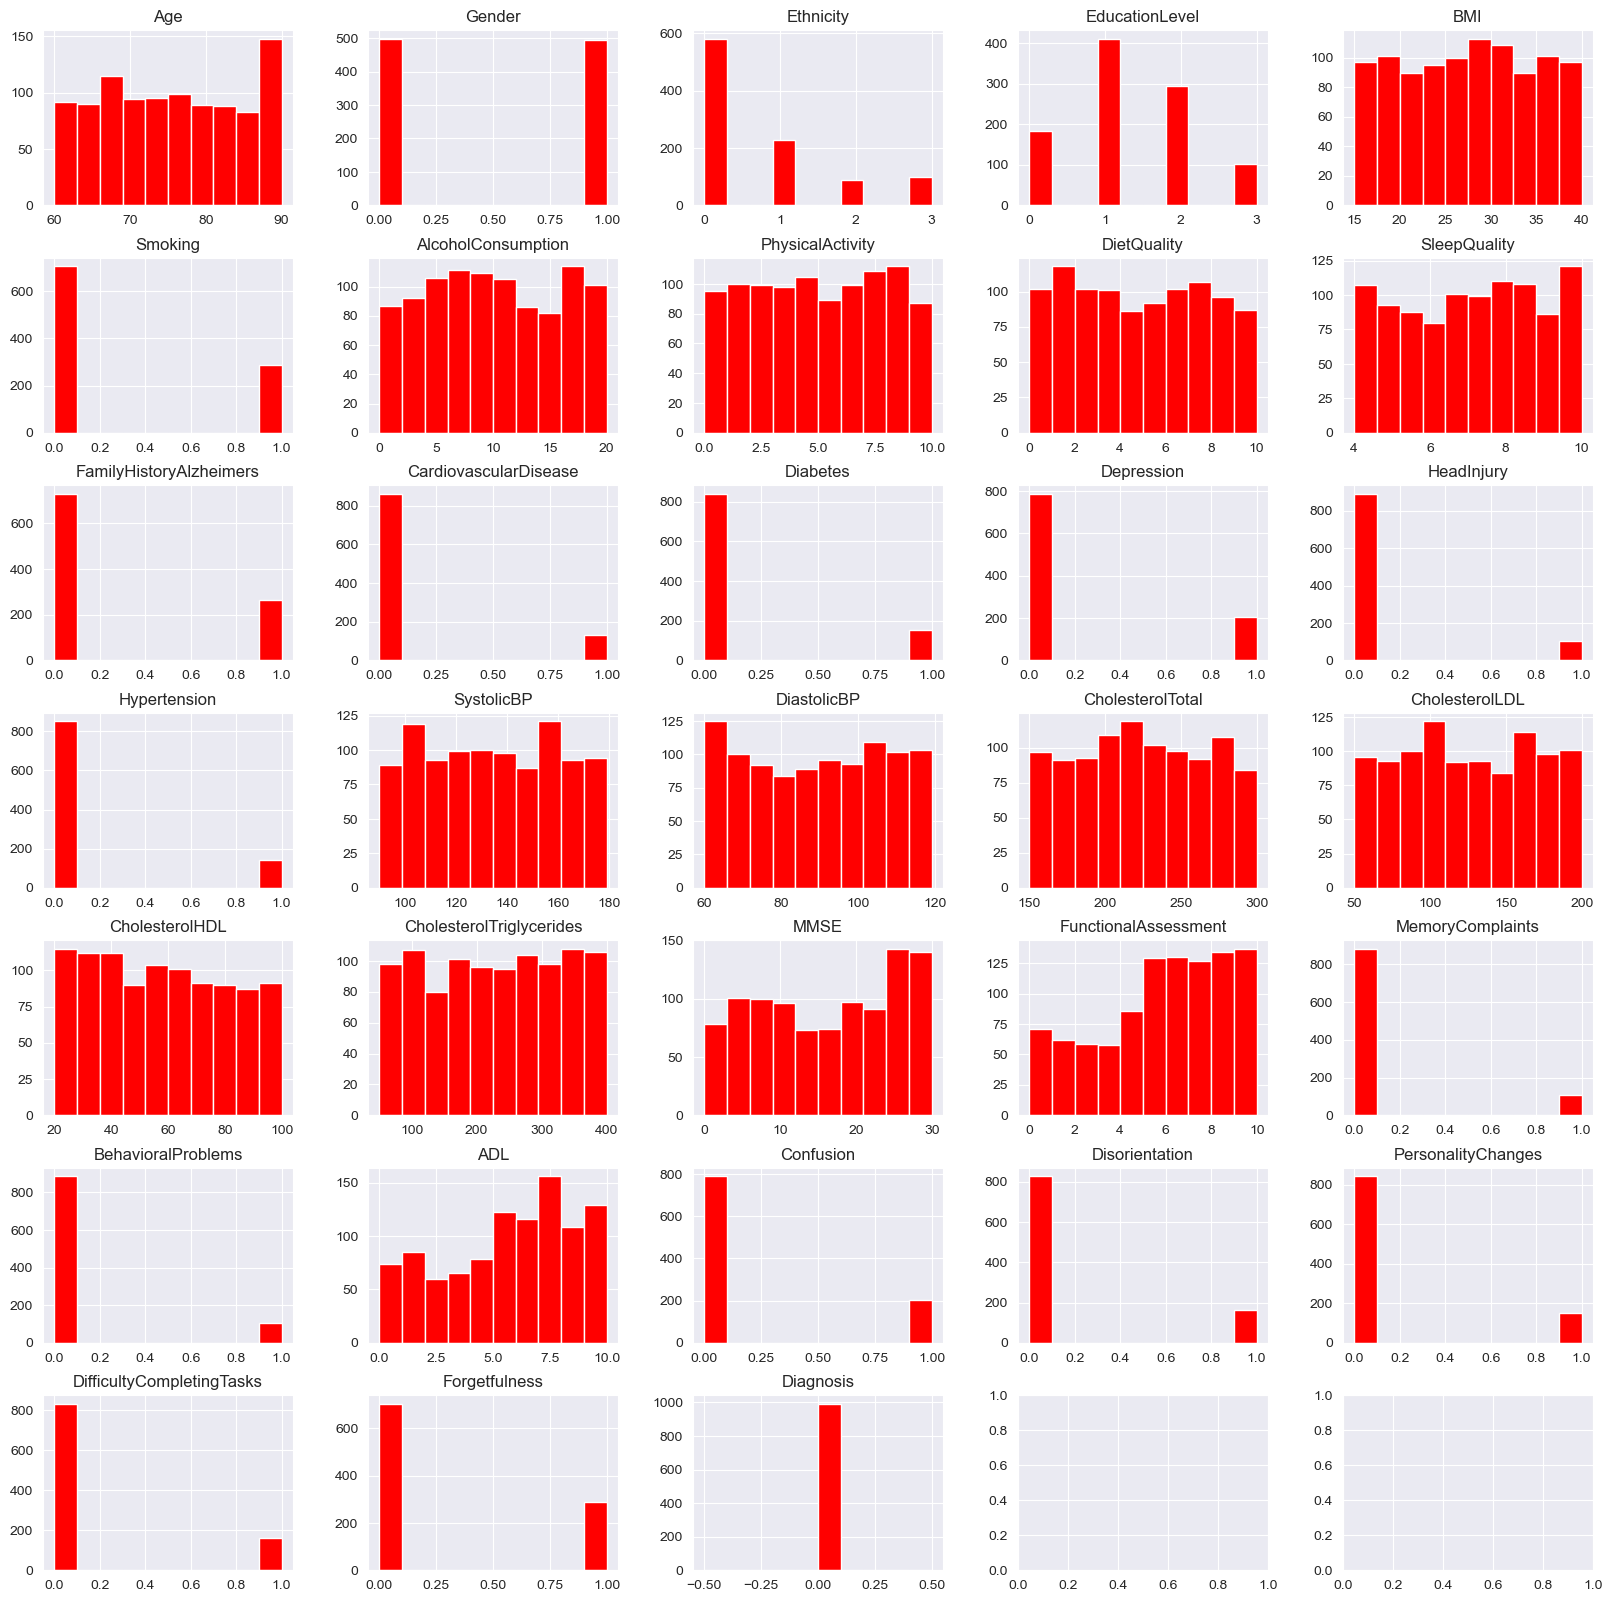

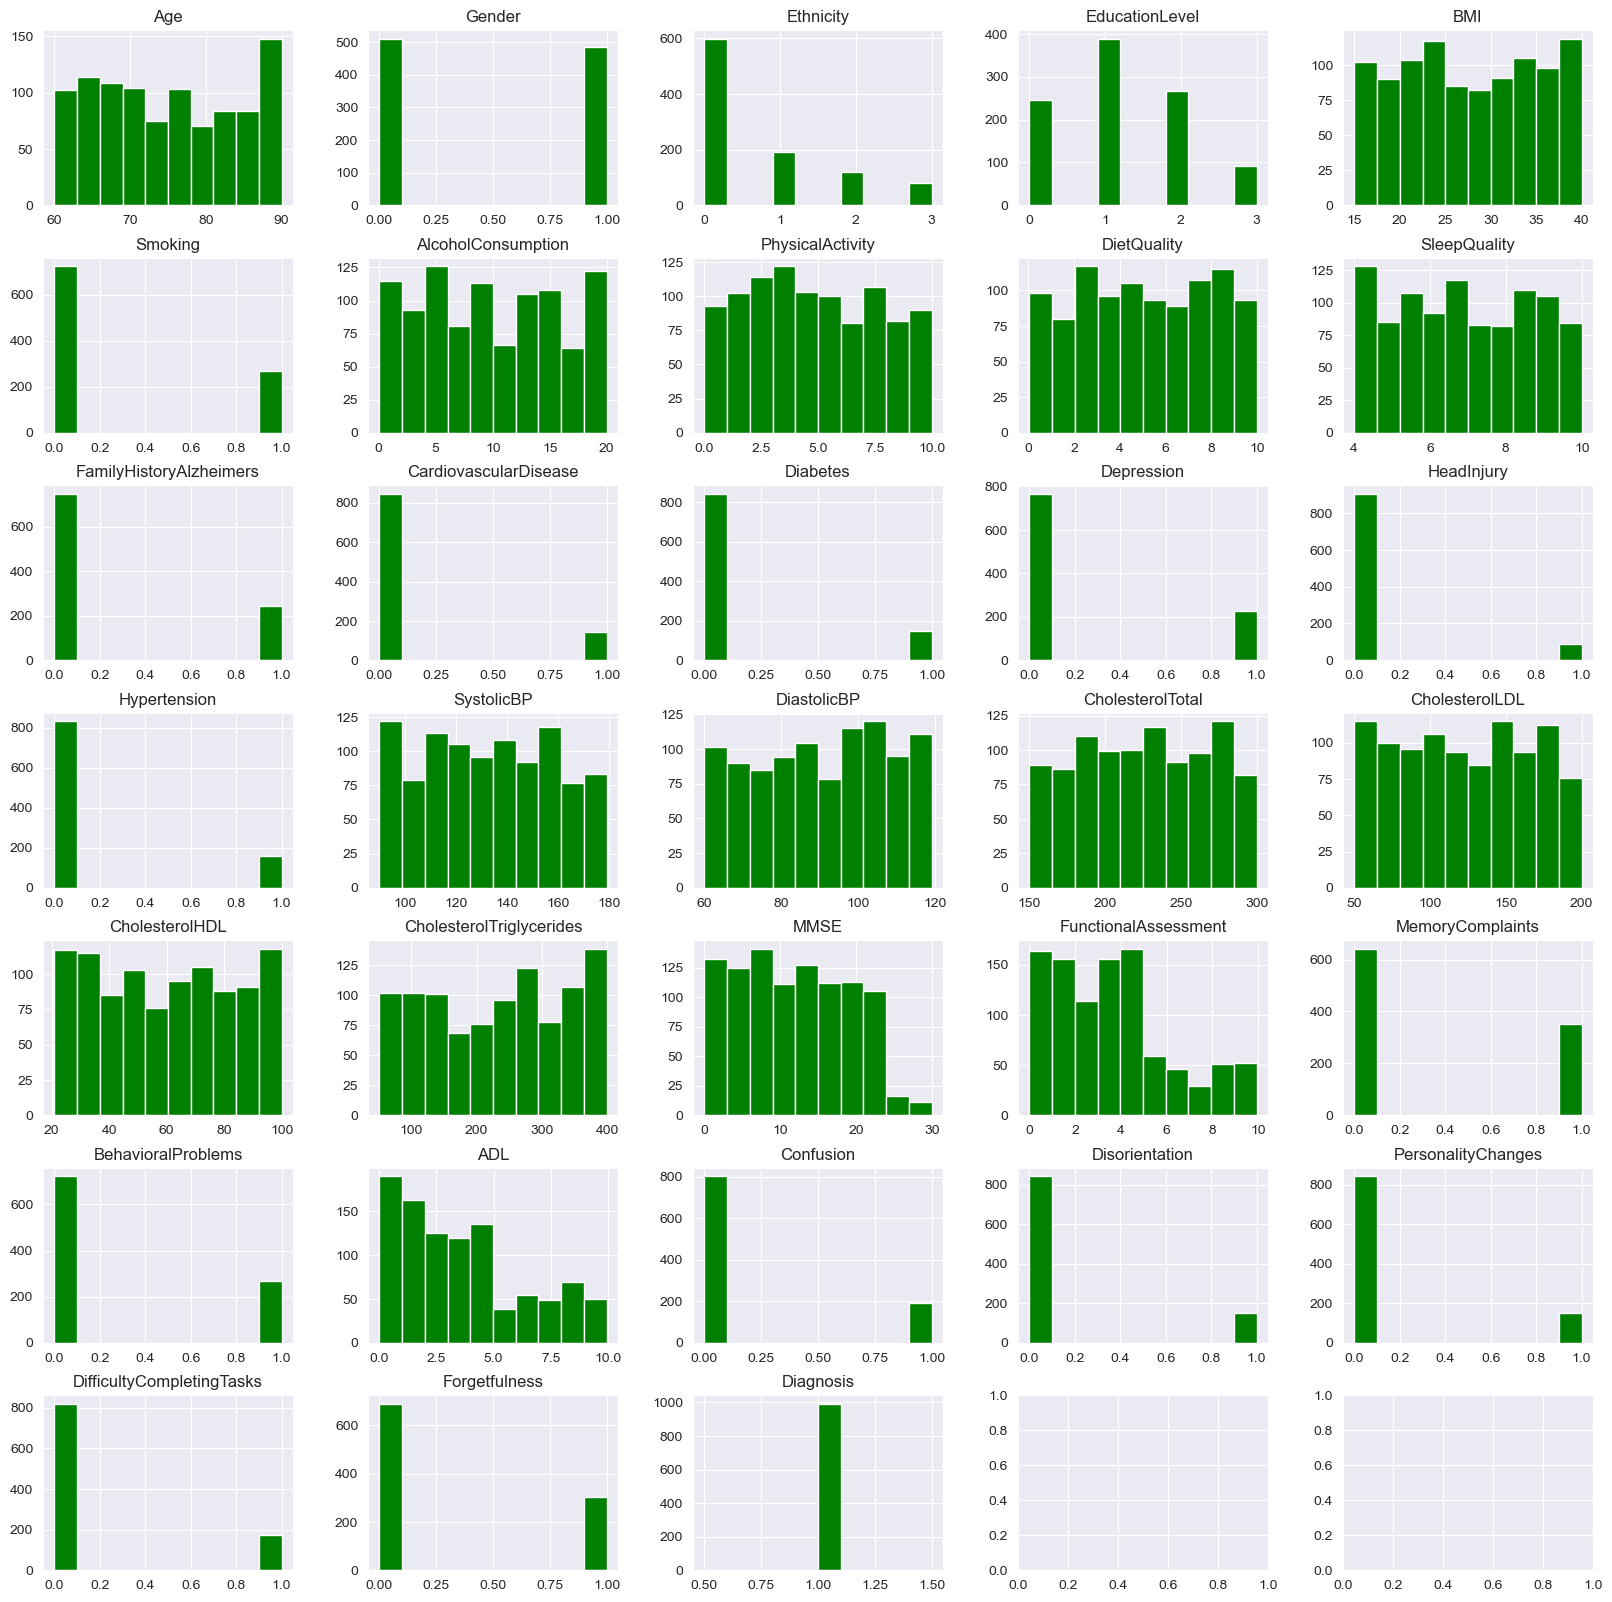

In [41]:
# CELL 13
# More Data Wrangling

# visualization of TRAINING (OVERSAMPLED) dataset AFTER HAVING REMOVED UNNECESSARY COLUMNS, for comparing distribution of data samples BETWEEN POSITIVE AND NEGATIVE DIAGNOSIS across features.
# The dataset has already been split into train, validation and test subsets and the training dataset resampled. alzheimers_temp_concat_resampled_df is only a temporary variable that will NOT be used. In alzheimers_temp_concat_resampled_df, X_resampled and y_resampled are only merged for visualization purposes, so we can visually analyse and verify that the training dataset has indeed been resampled and is not balanced.
alzheimers_temp_concat_resampled_df = pd.concat([X_over_sampled, y_over_sampled], axis=1)
alzheimers_numerical_df = alzheimers_temp_concat_resampled_df.select_dtypes(include='number')  # select numeric columns only
alzheimers_negative_df = alzheimers_numerical_df[alzheimers_temp_concat_resampled_df['Diagnosis'] == 0]
alzheimers_positive_df = alzheimers_numerical_df[alzheimers_temp_concat_resampled_df['Diagnosis'] == 1]
negative_resampled = (alzheimers_temp_concat_resampled_df['Diagnosis'] == 0).sum()
positive_resampled = (alzheimers_temp_concat_resampled_df['Diagnosis'] == 1).sum()

print(f"Negative count AFTER OVERSAMPLING: {negative_resampled}\nPositive count AFTER OVERSAMPLIING: {positive_resampled}")
# from X_over_sampled.shape[0], we know 2149 entries. So:
print(f"Percentage of patients/entries in dataset were diagnosis is negative AFTER OVERSAMPLING: {(negative_resampled / 2149)*100}\n Percentage of patients/entries in dataset were diagnosis is positive AFTER OVERSAMPLING: {(positive_resampled / 2149)*100}")

numCols = alzheimers_numerical_df.shape[1]  # get number of columns
fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')
            i = i + 1


fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')
            i = i + 1

'''fig, axisRows = plt.subplots(numCols // 5 + 1, 5, figsize=(20, 20))
i = 0
for axisCols in axisRows:
    for axis in axisCols:
        if (i < numCols):
            alzheimers_negative_df.hist(column=alzheimers_negative_df.columns[i], bins=10, ax=axis, color='red')
            alzheimers_positive_df.hist(column=alzheimers_positive_df.columns[i], bins=10, ax=axis, color='green')
            i = i + 1'''

Modelling:
- Random Forest
- Logistic Regression
- KMeans clustering

Modelling >> RandomForestClassifier for answering the first analytical question.

 1. What environmental and lifestyle factors contribute to the development or to the risk of developing Alzheimer's? This could indicate that some lifestyle factors contribute to the development of Alzheimer's to a greater extent than others.


In [42]:
# CELL 14
def random_forest(features, target, X_val, y_val, X_test, y_test): #https://www.geeksforgeeks.org/dsa/random-forest-classifier-using-scikit-learn/
# tutorial used to guide code for using results of the model to answer analytical question (i.e. code for Feature Importance Techniques): https://www.geeksforgeeks.org/machine-learning/feature-importance-with-random-forests/

    # Data preparation is an iterative process and may need to be revisited when using certain ML models, as some expect the data to be in a certain format or make assumptions about how the data is distributed. The features to be investigated for my first analytical question include ordinal, categorical nominal, and continuous numeric variables. RandomForest can handle features with different data attribute types, making it a justifiable choice for my first analytical question by NOT requiring any further data preparation (whether changes to the distribution of the data or data transformations). There are other reasons justifying the choice of RandomForest for this analytical question; further details can be found in the report.

    # Random Forest Classifier is NOT too sensitive to the scale of the features, so no need to rescale the data. However, it is always beneficial to rescale the data so, for now, comment out this code, but train the model on the scaled data once to see if the results or performance improve.
    #scaler = StandardScaler()
    #X_train = scaler.fit_transform(X_train)
    #X_test = scaler.transform(X_test)


    # stratified kfold cross validation for evaluation of model performance later on
    k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # build and train the model
    model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
    #model.set_params()

    param_grid1 = {
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 0.5],
    }

    param_grid2= {
    'n_estimators': [50, 62, 75, 87, 100],
    'max_depth': [5, 7, 10, 15, 20],
    'min_samples_split': [5, 10, 15, 20, 25],
    'min_samples_leaf': [10, 20, 25, 30, 35],
    'bootstrap': [True, False]
    }

    param_grid3 = {
    'n_estimators': [110, 120, 130], #200, 300, 400],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 3],
    'min_samples_leaf': [6, 8, 10],
    'bootstrap': [True, False]
    }

    param_grid_list = [param_grid2, param_grid3, param_grid1]
    test_pred = None
    test_accuracy = None

    for param_grid in param_grid_list:

        model = GridSearchCV(model,param_grid,cv=k_fold,scoring="accuracy",n_jobs=-1, refit=True)
        model.fit(features, target)
        best_params = model.best_params_
        print(f"\nBest parameters found by grid search are: {best_params}")
        model = model.best_estimator_

        #Validation of results using formal methods:
        #Validation metrics for Categorical variables: Accuracy, Accuracy by model sub-space (confusion matrix), Precision, F1, ROC, etc
        train_pred = model.predict(features)
        training_accuracy = accuracy_score(target, train_pred)
        val_pred = model.predict(X_val)
        validation_accuracy = accuracy_score(y_val, val_pred)
        accuracy_difference = training_accuracy - validation_accuracy
        print(f"Training accuracy: {training_accuracy * 100:.2f}% \nValidation accuracy: {validation_accuracy * 100:.2f}% \nAccuracy difference (checking for overfitting): {accuracy_difference * 100:.2f}%")

        k_fold_model = cross_val_score(model, features, target, cv=k_fold,scoring="accuracy")
        print(f"Accuracy: {k_fold_model.mean():.3f} (+/- {k_fold_model.std() * 2:.3f})")


    test_pred = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, test_pred)
    print(f"Testing accuracy: {test_accuracy * 100:.2f}%\n")

    print(f"Classification report for Random Forest Classifier (test dataset):\n {classification_report(y_test, test_pred)}\n")
    conf_matrix = confusion_matrix(y_test, test_pred, labels=model.classes_)
    conf_matrix_display = ConfusionMatrixDisplay(confusion_matrix=conf_matrix).plot()
    conf_matrix_display.ax_.set_title(f"Confusion Matrix Alzheimer vs No Alzheimer for potentially\ncontributing environmental and lifestyle factors:")

    # Use model to answer analytical question; interpret results:
    model_feature_importances = model.feature_importances_
    features_importance_zip = zip(features.columns, model_feature_importances) #model.feature_importances_)
    features_importance_zip_sorted = sorted(features_importance_zip, key=lambda x: x[1], reverse=True) # code suggested by built-in PyCharm AI assistant
    for name, importance in features_importance_zip_sorted: # code inspired by https://stackoverflow.com/questions/23900080/how-are-feature-importances-ordered-in-scikit-learns-randomforestregressor
        print(f"Feature name: {name}\nFeature Importance: {importance}\n")


    # Assess results of Random Forest for usage in data analysis. For this, the code of tutorial https://www.geeksforgeeks.org/machine-learning/feature-importance-with-random-forests/ was used
    # features importance: Gini importance
    feature_imp_df = pd.DataFrame({'Feature': features.columns, 'Gini Importance': model_feature_importances}).sort_values('Gini Importance', ascending=False)
    print(feature_imp_df)

    plt.figure(figsize=(8, 4))
    plt.barh(features.columns, model_feature_importances, color='skyblue')
    plt.xlabel('Gini Importance')
    plt.title('Feature Importance - Gini Importance')
    plt.gca().invert_yaxis()
    plt.show()

    # feature importance: Mean Decrease Accuracy (MDA)
    importances = []
    for i in range(X_test.shape[1]):
        X_test_copy = X_test.copy()
        shuffled_col = X_test_copy.iloc[:, i].values.copy() # code suggested by built-in PyCharm AI assistant
        np.random.shuffle(shuffled_col) # code suggested by built-in PyCharm AI assistant
        X_test_copy.iloc[:, i] = shuffled_col # code suggested by built-in PyCharm AI assistant
        shuff_accuracy = accuracy_score(y_test, model.predict(X_test_copy))
        importances.append(test_accuracy - shuff_accuracy)
    accuracy_df = pd.DataFrame({'Feature': features.columns, 'Decrease in Accuracy': importances}).sort_values('Decrease in Accuracy', ascending=False)
    print(accuracy_df)

    plt.figure(figsize=(8, 4))
    plt.barh(features.columns, importances, color='skyblue')
    plt.xlabel('Mean Decrease Accuracy')
    plt.title('Feature Importance - Mean Decrease Accuracy')
    plt.gca().invert_yaxis()
    plt.show()

    # feature importance: Permutation Feature Importance
    result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
    perm_imp_df = pd.DataFrame({'Feature': features.columns, 'Permutation Importance': result.importances_mean}).sort_values('Permutation Importance', ascending=False)
    print(perm_imp_df)

    plt.figure(figsize=(6, 6))
    plt.bar(perm_imp_df['Feature'], perm_imp_df['Permutation Importance'])
    plt.xlabel('Feature')
    plt.ylabel('Permutation Importance')
    plt.title('Permutation Feature Importance')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # feature importance: SHAP values (SHapley Additive exPlanations)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    # The development of the following code using shap for separating between classes was aided by chatGPT
    # --- Handle binary classification safely ---
    if isinstance(shap_values, list):
        # Old / classic SHAP behavior
        shap_class_0 = shap_values[0]
        shap_class_1 = shap_values[1]
    else:
        # New SHAP behavior (single array = positive class)
        shap_class_1 = shap_values
        shap_class_0 = -shap_values


    print("Features contributing to POSITIVE diagnosis (Class 1)")
    shap.summary_plot(
        shap_class_1,
        X_test,
        feature_names=X_test.columns,
        show=True
    )

    # --- Plot: class 0 (negative diagnosis) ---
    print("Features contributing to NEGATIVE diagnosis (Class 0)")
    shap.summary_plot(
        shap_class_0,
        X_test,
        feature_names=X_test.columns,
        show=True
    )

    # --- Separate SHAP values by class ---
    if isinstance(shap_values, list):
        # Classic SHAP: list of arrays
        shap_pos = shap_values[1]  # class 1 (positive diagnosis)
        shap_neg = shap_values[0]  # class 0 (negative diagnosis)
    else:
        # New SHAP: single array = positive class
        shap_pos = shap_values
        shap_neg = -shap_values


    if isinstance(shap_pos, list):
        shap_summary_pos = np.mean(np.abs(np.stack(shap_pos)), axis=(0, 1))
    else:
        shap_summary_pos = np.abs(shap_pos).mean(axis=0)

    shap_summary_pos = shap_summary_pos.flatten()
    shap_summary_pos = shap_summary_pos[:len(features.columns)]

    # --- Build DataFrames ---
    df_pos = pd.DataFrame({
        'Feature': features.columns,
        'Mean |SHAP| (Positive Diagnosis)': shap_summary_pos #mean_abs_shap_pos
    }).sort_values('Mean |SHAP| (Positive Diagnosis)', ascending=False)

    # --- Display tables ---
    print("\nTop features contributing to POSITIVE diagnosis:")
    print(df_pos)

    plt.figure(figsize=(8, 4))
    plt.barh(df_pos['Feature'],
             df_pos['Mean |SHAP| (Positive Diagnosis)'], color='skyblue')
    plt.xlabel('Mean SHAP Value POSITIVE DIAGNOSIS')
    plt.title('Feature Importance (SHAP Values) POSITIVE DIAGNOSIS')
    plt.gca().invert_yaxis()
    plt.show()

    if isinstance(shap_neg, list):
        shap_summary_neg = np.mean(np.abs(np.stack(shap_neg)), axis=(0, 1))
    else:
        shap_summary_neg = np.abs(shap_neg).mean(axis=0)

    shap_summary_neg = shap_summary_neg.flatten()
    shap_summary_neg = shap_summary_neg[:len(features.columns)]


    df_neg = pd.DataFrame({
        'Feature': features.columns,
        'Mean |SHAP| (Negative Diagnosis)': shap_summary_neg #mean_abs_shap_neg
    }).sort_values('Mean |SHAP| (Negative Diagnosis)', ascending=False)

    print("\nTop features contributing to NEGATIVE diagnosis:")
    print(df_neg)

    plt.figure(figsize=(8, 4))
    plt.barh(df_neg['Feature'],
             df_neg['Mean |SHAP| (Negative Diagnosis)'], color='skyblue')
    plt.xlabel('Mean SHAP Value NEGATIVE DIAGNOSIS')
    plt.title('Feature Importance (SHAP Values) NEGATIVE DIAGNOSIS')
    plt.gca().invert_yaxis()
    plt.show()

    if isinstance(shap_values, list):
        shap_summary = np.mean(np.abs(np.stack(shap_values)), axis=(0, 1))
    else:
        shap_summary = np.abs(shap_values).mean(axis=0)

    shap_summary = shap_summary.flatten()
    shap_summary = shap_summary[:len(features.columns)]

    shap_summary_df = pd.DataFrame({
        'Feature': features.columns,
        'Mean |SHAP Value|': shap_summary
    }).sort_values('Mean |SHAP Value|', ascending=False)

    print(shap_summary_df)
    plt.figure(figsize=(8, 4))
    plt.barh(shap_summary_df['Feature'],
             shap_summary_df['Mean |SHAP Value|'], color='skyblue')
    plt.xlabel('Mean Absolute SHAP Value')
    plt.title('Feature Importance (SHAP Values)')
    plt.gca().invert_yaxis()
    plt.show()






    return model

Random Forest Classifier trained with UNDERSAMPLED (balanced) dataset and only features relevant to the first analytical question:

Best parameters found by grid search are: {'bootstrap': False, 'max_depth': 5, 'min_samples_leaf': 25, 'min_samples_split': 5, 'n_estimators': 87}
Training accuracy: 65.70% 
Validation accuracy: 43.60% 
Accuracy difference (checking for overfitting): 22.10%
Accuracy: 0.523 (+/- 0.052)

Best parameters found by grid search are: {'bootstrap': True, 'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 2, 'n_estimators': 110}
Training accuracy: 90.61% 
Validation accuracy: 46.51% 
Accuracy difference (checking for overfitting): 44.10%
Accuracy: 0.514 (+/- 0.036)

Best parameters found by grid search are: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 10}
Training accuracy: 90.61% 
Validation accuracy: 46.51% 
Accuracy difference (checking for overfitting): 44.10%
Accuracy: 0.514 (+/- 0.036)
Testing accuracy: 43.95%

Classification repor

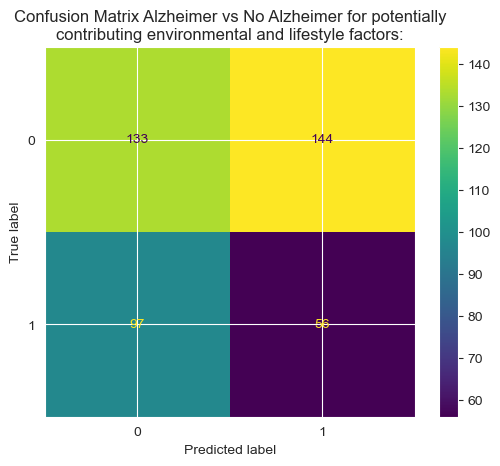

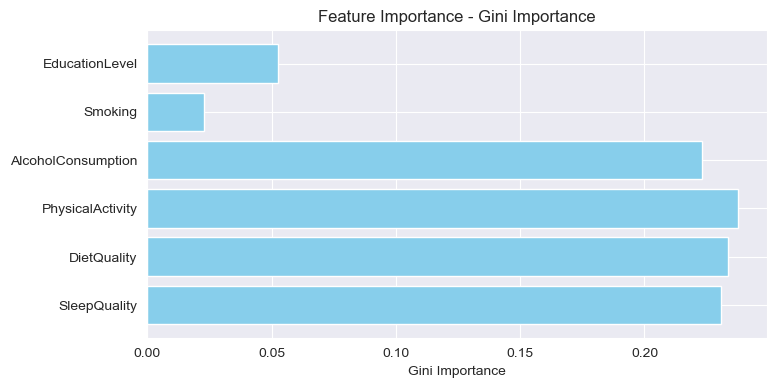

              Feature  Decrease in Accuracy
2  AlcoholConsumption              0.002326
1             Smoking              0.000000
4         DietQuality             -0.011628
5        SleepQuality             -0.013953
0      EducationLevel             -0.041860
3    PhysicalActivity             -0.048837


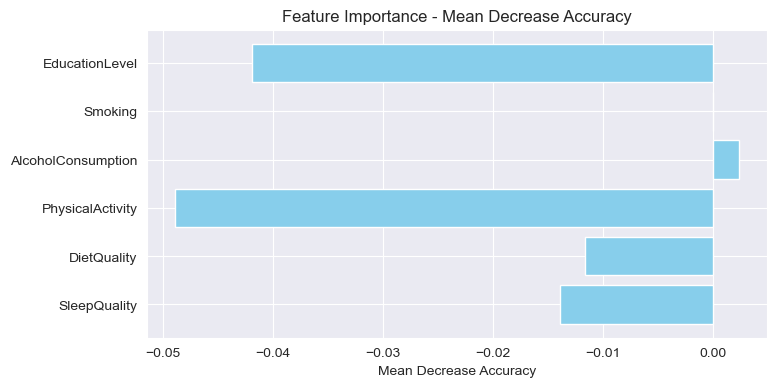

              Feature  Permutation Importance
0      EducationLevel               -0.013023
4         DietQuality               -0.016512
1             Smoking               -0.016977
5        SleepQuality               -0.022093
2  AlcoholConsumption               -0.030233
3    PhysicalActivity               -0.053488


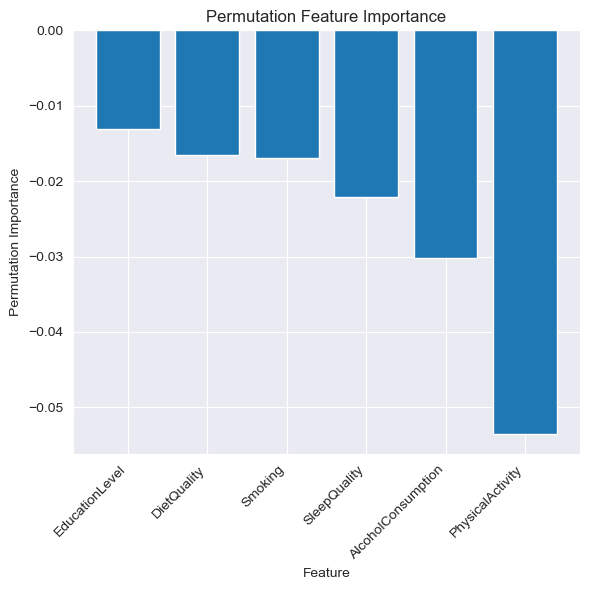

Features contributing to POSITIVE diagnosis (Class 1)


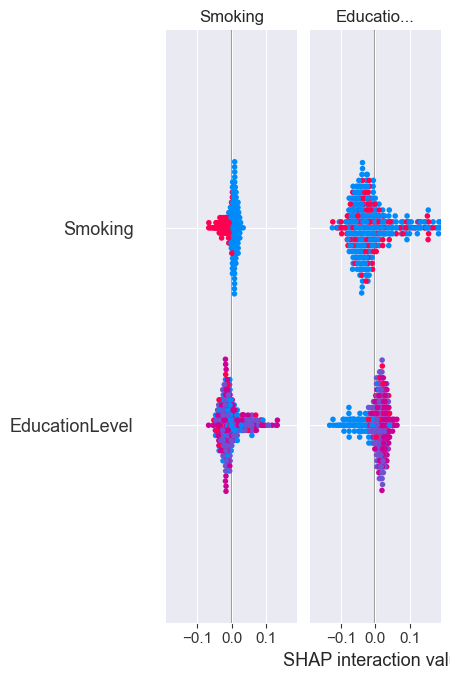

Features contributing to NEGATIVE diagnosis (Class 0)


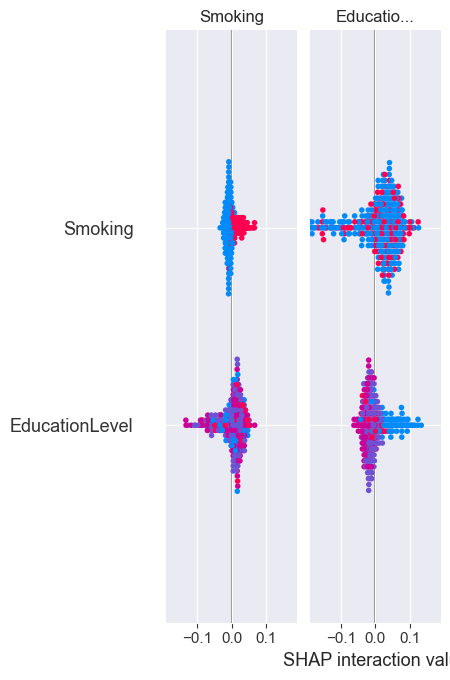


Top features contributing to POSITIVE diagnosis:
              Feature  Mean |SHAP| (Positive Diagnosis)
4         DietQuality                          0.034342
5        SleepQuality                          0.034342
0      EducationLevel                          0.026763
1             Smoking                          0.026763
3    PhysicalActivity                          0.012964
2  AlcoholConsumption                          0.012964


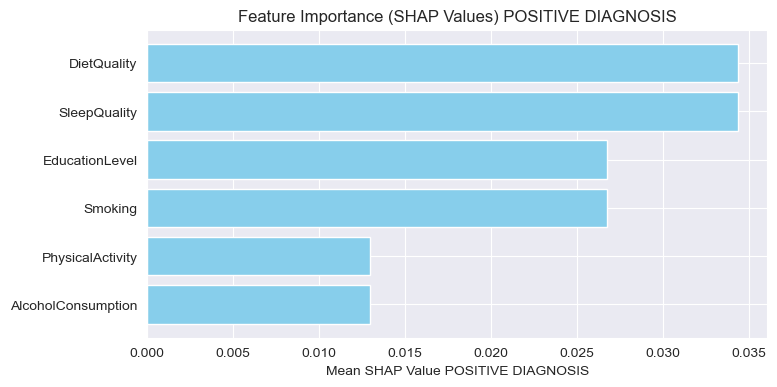


Top features contributing to NEGATIVE diagnosis:
              Feature  Mean |SHAP| (Negative Diagnosis)
4         DietQuality                          0.034342
5        SleepQuality                          0.034342
0      EducationLevel                          0.026763
1             Smoking                          0.026763
3    PhysicalActivity                          0.012964
2  AlcoholConsumption                          0.012964


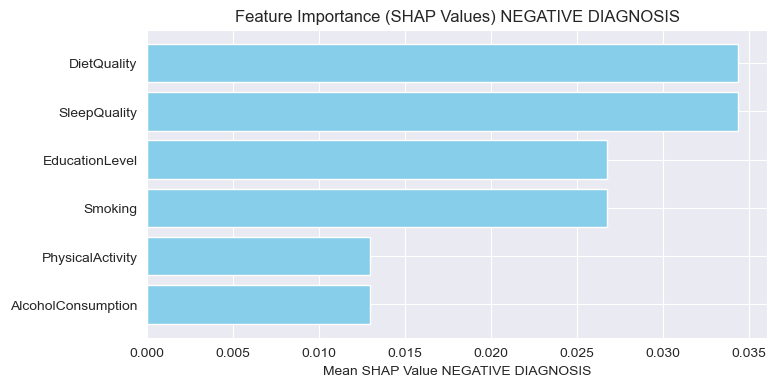

              Feature  Mean |SHAP Value|
4         DietQuality           0.034342
5        SleepQuality           0.034342
0      EducationLevel           0.026763
1             Smoking           0.026763
3    PhysicalActivity           0.012964
2  AlcoholConsumption           0.012964


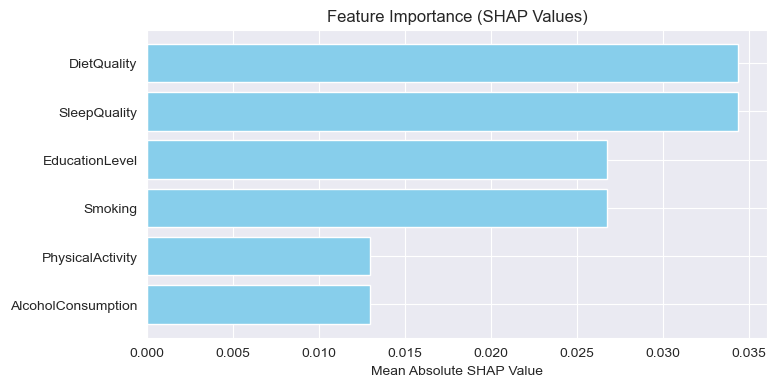

In [43]:
# CELL 15
if __name__ == "__main__":
    print("Random Forest Classifier trained with UNDERSAMPLED (balanced) dataset and only features relevant to the first analytical question:")
    undersampled = random_forest(X_under_sampled_features_q1, y_under_sampled, X_val_q1, y_val, X_test_q1, y_test)



Random Forest Classifier trained with OVERSAMPLED (balanced) dataset and only features relevant to the first analytical question:

Best parameters found by grid search are: {'bootstrap': True, 'max_depth': 20, 'min_samples_leaf': 10, 'min_samples_split': 5, 'n_estimators': 62}
Training accuracy: 92.75% 
Validation accuracy: 52.33% 
Accuracy difference (checking for overfitting): 40.42%
Accuracy: 0.660 (+/- 0.011)

Best parameters found by grid search are: {'bootstrap': False, 'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 2, 'n_estimators': 110}
Training accuracy: 97.18% 
Validation accuracy: 61.05% 
Accuracy difference (checking for overfitting): 36.13%
Accuracy: 0.692 (+/- 0.034)

Best parameters found by grid search are: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Training accuracy: 99.80% 
Validation accuracy: 59.30% 
Accuracy difference (checking for overfitting): 40.50%
Accuracy: 0.721 (+/- 0.048)
Testing accuracy: 57.44%

Classification report 

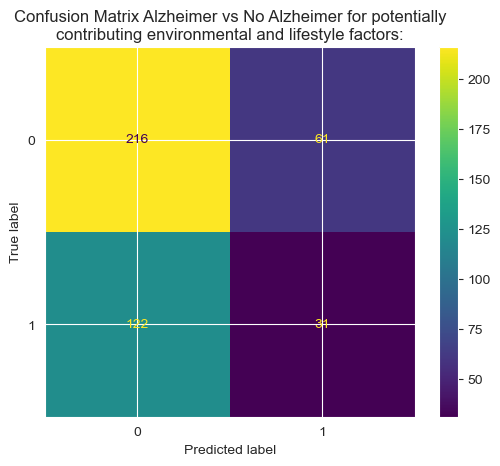

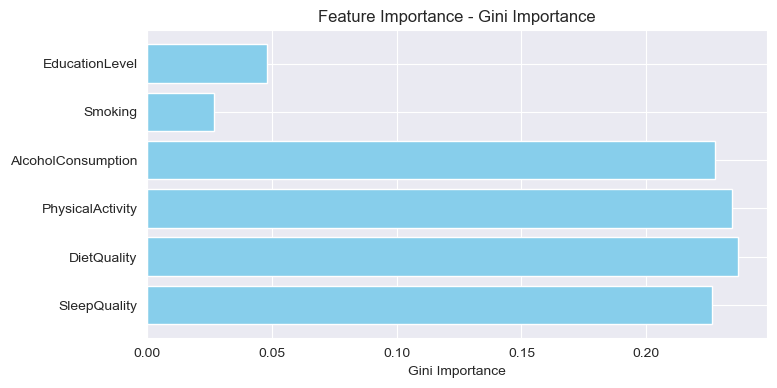

              Feature  Decrease in Accuracy
5        SleepQuality              0.046512
2  AlcoholConsumption              0.041860
0      EducationLevel              0.000000
4         DietQuality              0.000000
1             Smoking             -0.009302
3    PhysicalActivity             -0.027907


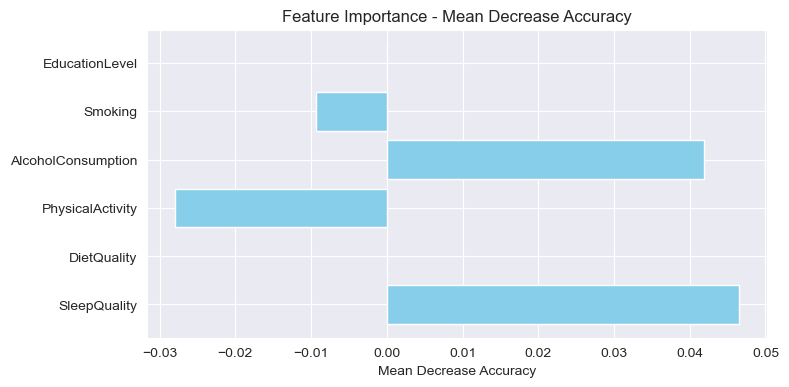

              Feature  Permutation Importance
5        SleepQuality                0.028837
0      EducationLevel                0.025349
2  AlcoholConsumption                0.013023
4         DietQuality                0.011628
3    PhysicalActivity               -0.009302
1             Smoking               -0.010233


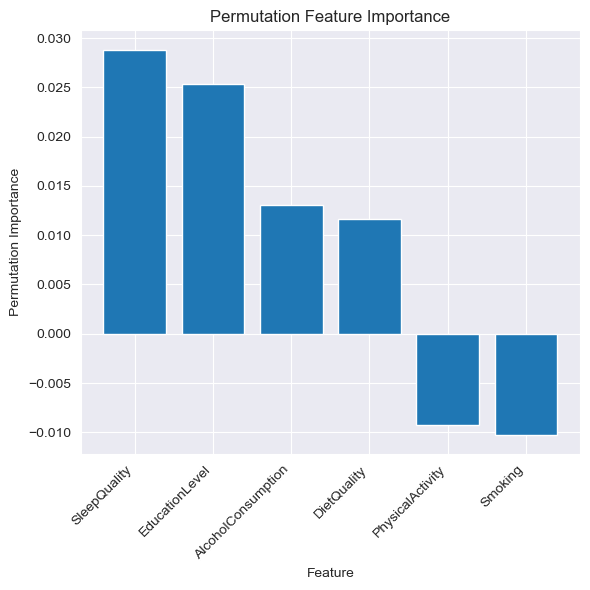

Features contributing to POSITIVE diagnosis (Class 1)


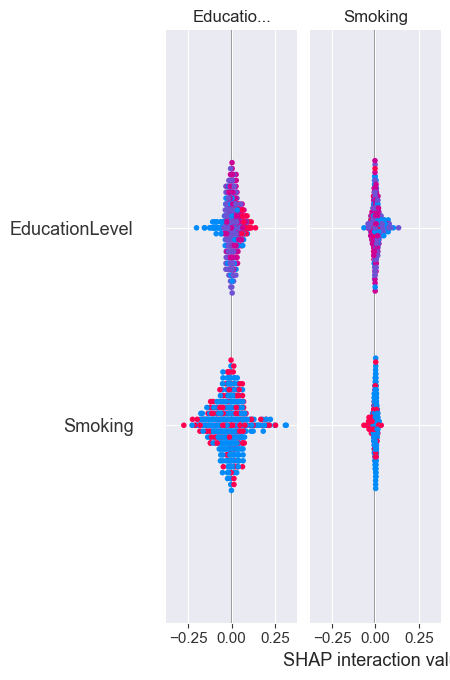

Features contributing to NEGATIVE diagnosis (Class 0)


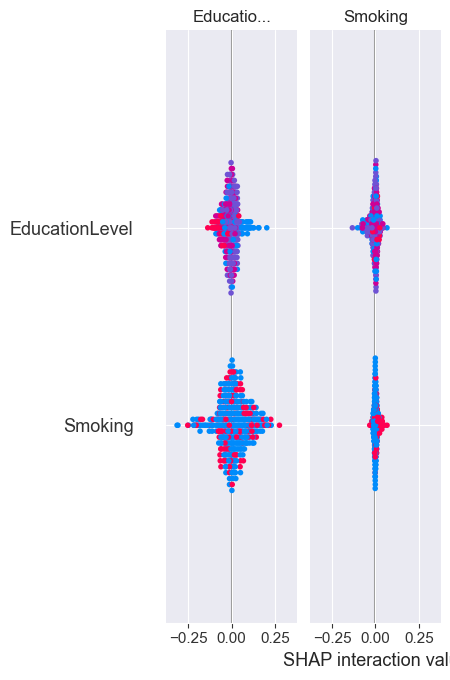


Top features contributing to POSITIVE diagnosis:
              Feature  Mean |SHAP| (Positive Diagnosis)
4         DietQuality                          0.040984
5        SleepQuality                          0.040984
0      EducationLevel                          0.032273
1             Smoking                          0.032273
3    PhysicalActivity                          0.008069
2  AlcoholConsumption                          0.008069


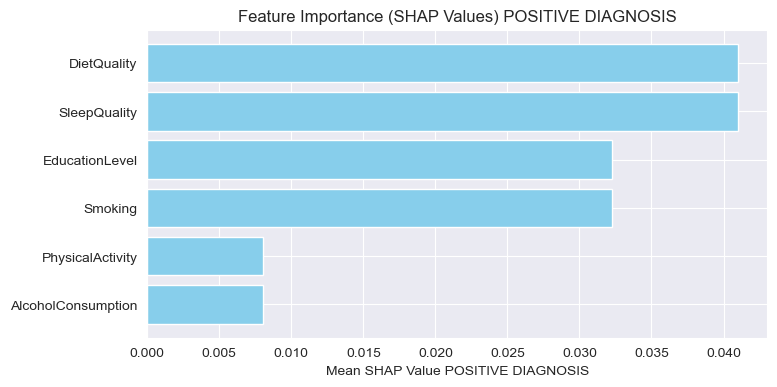


Top features contributing to NEGATIVE diagnosis:
              Feature  Mean |SHAP| (Negative Diagnosis)
4         DietQuality                          0.040984
5        SleepQuality                          0.040984
0      EducationLevel                          0.032273
1             Smoking                          0.032273
3    PhysicalActivity                          0.008069
2  AlcoholConsumption                          0.008069


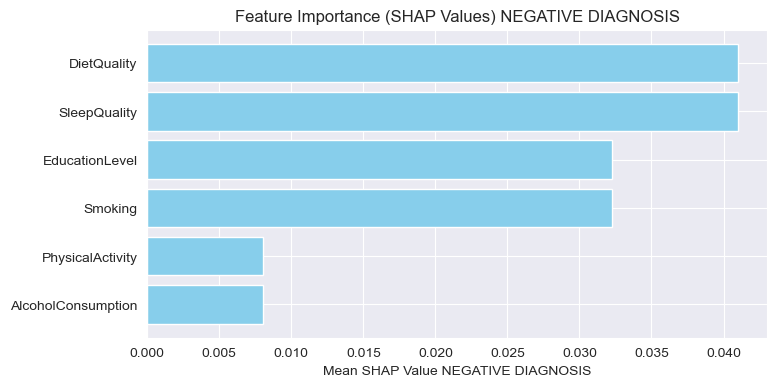

              Feature  Mean |SHAP Value|
4         DietQuality           0.040984
5        SleepQuality           0.040984
0      EducationLevel           0.032273
1             Smoking           0.032273
3    PhysicalActivity           0.008069
2  AlcoholConsumption           0.008069


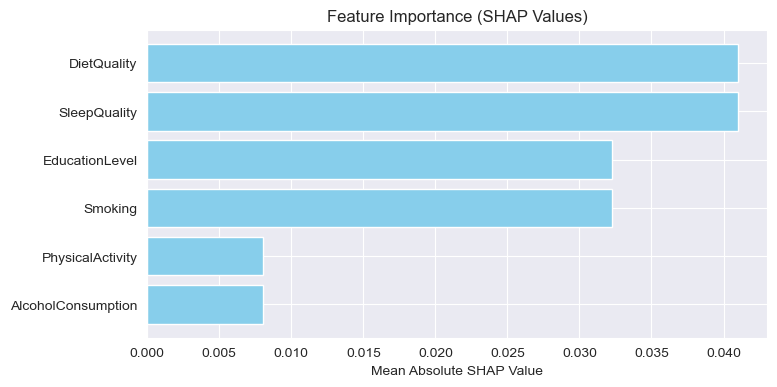

In [44]:
# CELL 16
if __name__ == "__main__":
    print("Random Forest Classifier trained with OVERSAMPLED (balanced) dataset and only features relevant to the first analytical question:")
    oversampled = random_forest(X_over_sampled_features_q1, y_over_sampled, X_val_q1, y_val, X_test_q1, y_test)





Random Forest Classifier trained with original (unbalanced) dataset and only features relevant to the first analytical question:

Best parameters found by grid search are: {'bootstrap': True, 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 5, 'n_estimators': 100}
Training accuracy: 65.74% 
Validation accuracy: 41.86% 
Accuracy difference (checking for overfitting): 23.88%
Accuracy: 0.520 (+/- 0.041)

Best parameters found by grid search are: {'bootstrap': False, 'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 2, 'n_estimators': 110}
Training accuracy: 93.99% 
Validation accuracy: 48.26% 
Accuracy difference (checking for overfitting): 45.73%
Accuracy: 0.513 (+/- 0.037)

Best parameters found by grid search are: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 5}
Training accuracy: 93.41% 
Validation accuracy: 49.42% 
Accuracy difference (checking for overfitting): 43.99%
Accuracy: 0.520 (+/- 0.041)
Testing accuracy: 46.98%

Classification report f

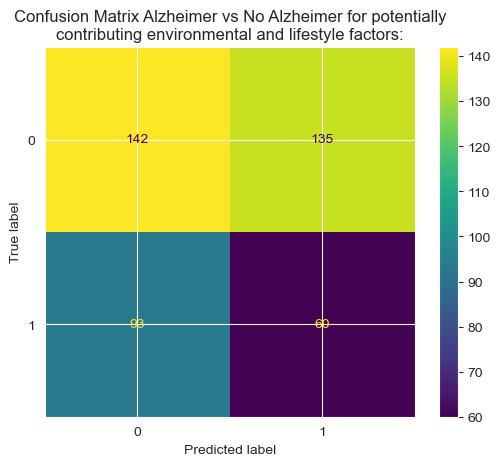

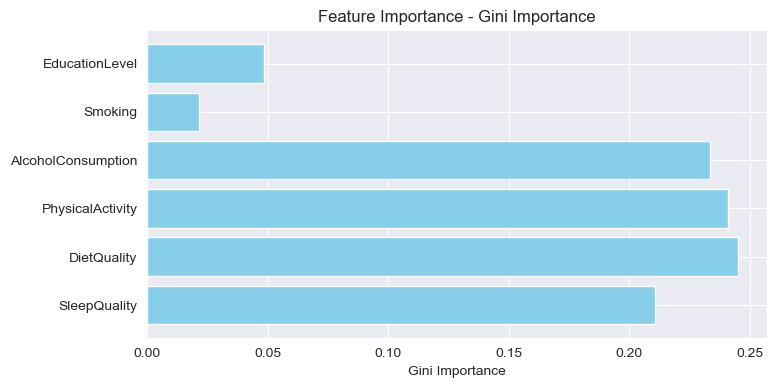

              Feature  Decrease in Accuracy
5        SleepQuality              0.018605
2  AlcoholConsumption              0.000000
1             Smoking             -0.011628
4         DietQuality             -0.018605
0      EducationLevel             -0.023256
3    PhysicalActivity             -0.039535


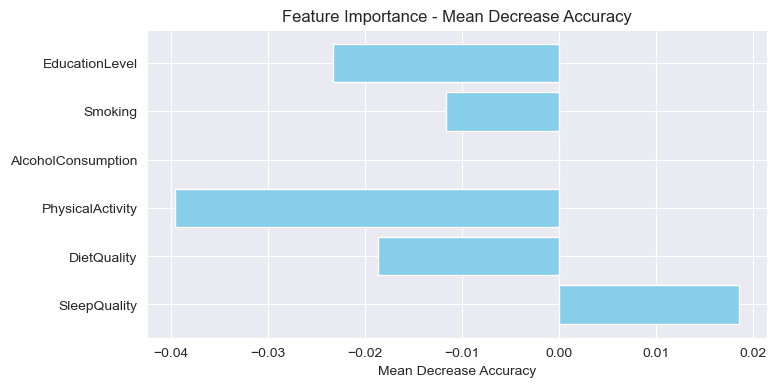

              Feature  Permutation Importance
5        SleepQuality                0.008605
4         DietQuality                0.000233
2  AlcoholConsumption               -0.007209
1             Smoking               -0.010698
0      EducationLevel               -0.014651
3    PhysicalActivity               -0.037209


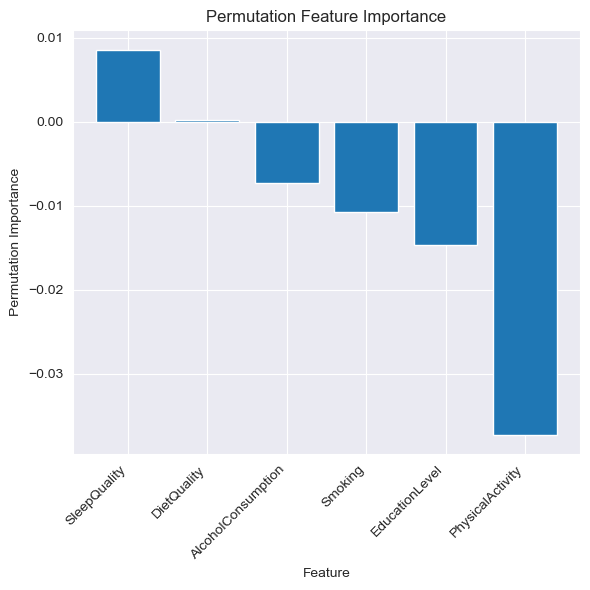

Features contributing to POSITIVE diagnosis (Class 1)


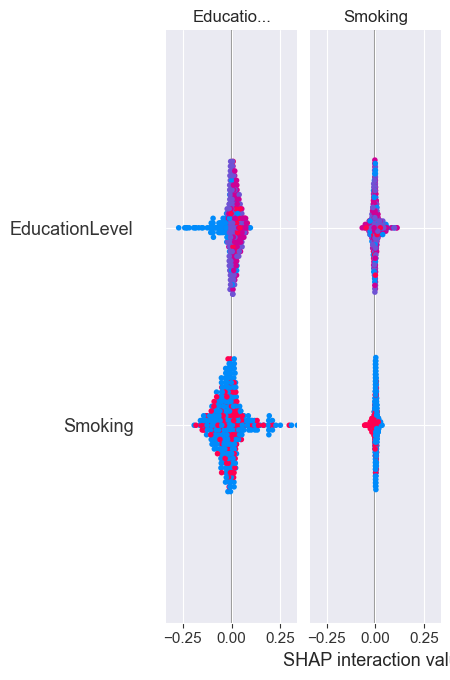

Features contributing to NEGATIVE diagnosis (Class 0)


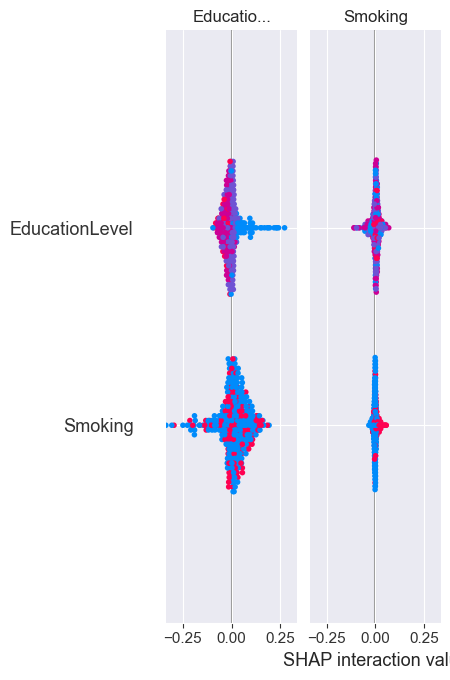


Top features contributing to POSITIVE diagnosis:
              Feature  Mean |SHAP| (Positive Diagnosis)
5        SleepQuality                          0.049789
4         DietQuality                          0.049789
0      EducationLevel                          0.029931
1             Smoking                          0.029931
2  AlcoholConsumption                          0.006426
3    PhysicalActivity                          0.006426


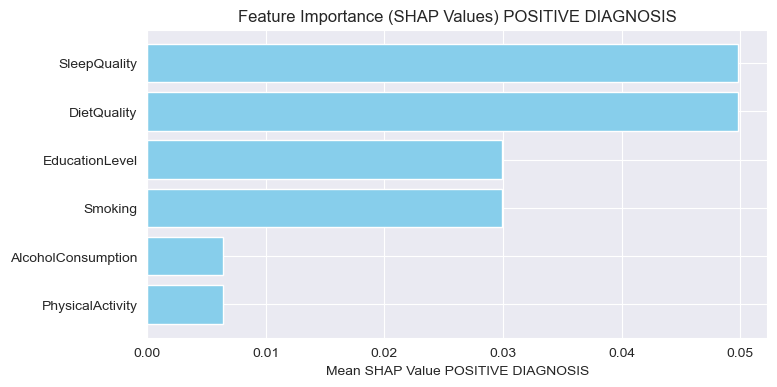


Top features contributing to NEGATIVE diagnosis:
              Feature  Mean |SHAP| (Negative Diagnosis)
5        SleepQuality                          0.049789
4         DietQuality                          0.049789
0      EducationLevel                          0.029931
1             Smoking                          0.029931
2  AlcoholConsumption                          0.006426
3    PhysicalActivity                          0.006426


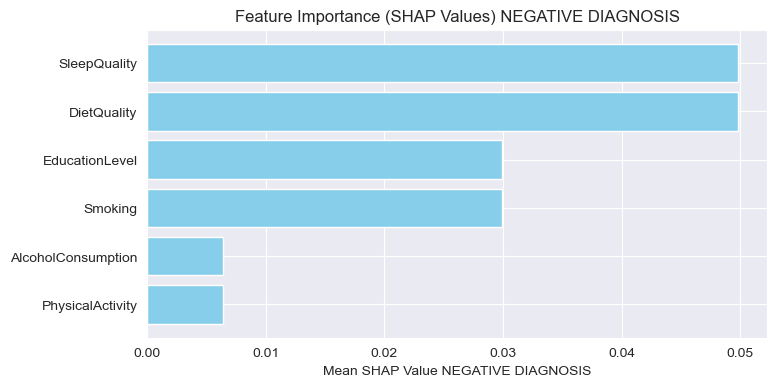

              Feature  Mean |SHAP Value|
5        SleepQuality           0.049789
4         DietQuality           0.049789
0      EducationLevel           0.029931
1             Smoking           0.029931
2  AlcoholConsumption           0.006426
3    PhysicalActivity           0.006426


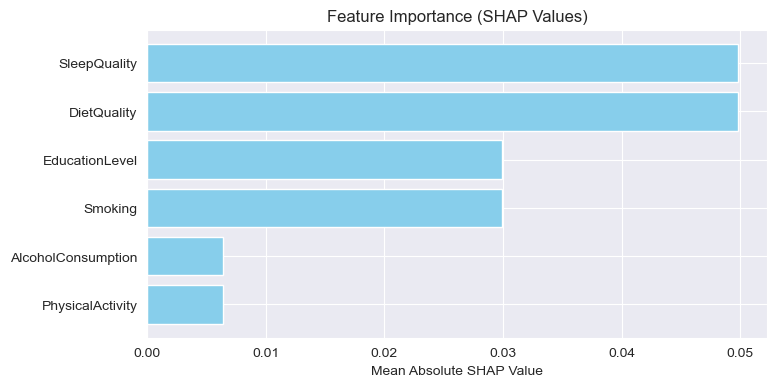

In [45]:
# CELL 17
if __name__ == "__main__":
    print("\n\n\nRandom Forest Classifier trained with original (unbalanced) dataset and only features relevant to the first analytical question:")
    unbalanced = random_forest(X_features_q1, y_train, X_val_q1, y_val, X_test_q1, y_test)


Modelling >> LogisticRegression for answering the second analytical question.

What clinical measurements are most prevalent in patients suffering from Alzheimer's? Perhaps
this be used to aid in early diagnostic techniques, with routine tests such as blood analysis being
useful in identifying patients at early stages or at risk of developing the disease. The literature fails
to study the relationship between clinical measurements such as blood pressure and cholesterol
levels and the development of Alzheimer’s.
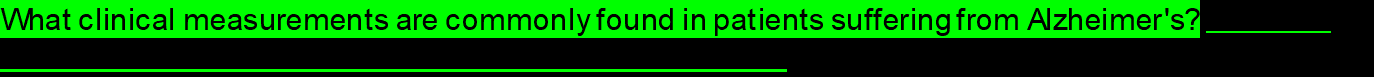
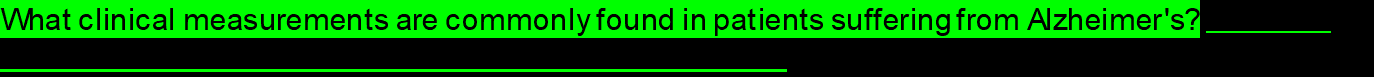

In [46]:
# CELL 18
# CODE LOGISTIC REGRESSION FOR QUESTION 2
# tutorial used to guide code for using results of the model to answer analytical question (i.e. code for Feature Importance Techniques): https://www.geeksforgeeks.org/machine-learning/understanding-feature-importance-in-logistic-regression-models/

def logistic_regression(features, target, X_val, y_val, X_test, y_test):

    # build and train the model
    logistic_regression_model = LogisticRegression(max_iter=10000, solver='liblinear', random_state=42)

    # stratified kfold cross validation for evaluation of model performance later on
    k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    param_grid1 = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": [None, "balanced"]
    }

    #'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'
    param_grid2 = {
    "C": [0.0001, 0.001, 0.01, 0.1],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": ["balanced"]
    }

    param_grid3 = {
    "C": [0.0001, 0.001, 0.01, 0.1],
    "penalty": ["elasticnet"],
    "solver": ["saga"],
    "class_weight": ["balanced"],
    "l1_ratio": np.linspace(0, 1, 10)
    }

    param_grid_list = [param_grid1, param_grid2, param_grid3] #[param_grid2, param_grid3, param_grid1]
    test_pred = None
    test_accuracy = None

    for param_grid in param_grid_list:

        logistic_regression_model = GridSearchCV(logistic_regression_model,param_grid,cv=k_fold,scoring="accuracy",n_jobs=-1, refit=True)
        logistic_regression_model.fit(features, target)
        best_params = logistic_regression_model.best_params_
        print(f"\nBest parameters found by grid search are: {best_params}")
        logistic_regression_model = logistic_regression_model.best_estimator_

        # Validation of results using formal methods:
        #Validation metrics for Categorical variables: Accuracy, Accuracy by model sub-space (confusion matrix), Precision, F1, ROC, etc
        train_pred_lr = logistic_regression_model.predict(features)
        training_accuracy_lr = accuracy_score(target, train_pred_lr)
        val_pred_lr = logistic_regression_model.predict(X_val)
        validation_accuracy_lr = accuracy_score(y_val, val_pred_lr)
        accuracy_difference_lr = training_accuracy_lr - validation_accuracy_lr
        print(f"Training accuracy: {training_accuracy_lr * 100:.2f}% \nValidation accuracy: {validation_accuracy_lr * 100:.2f}% \nAccuracy difference (checking for overfitting): {accuracy_difference_lr * 100:.2f}%")

        k_fold_model = cross_val_score(logistic_regression_model, features, target, cv=k_fold,scoring="accuracy")
        print(f"Accuracy: {k_fold_model.mean():.3f} (+/- {k_fold_model.std() * 2:.3f})")

    test_pred_lr = logistic_regression_model.predict(X_test)
    test_accuracy = accuracy_score(y_test, test_pred_lr)
    print(f"Testing accuracy: {test_accuracy * 100:.2f}%\n")
    print(f"Classification report for Logistic Regression Classifier (test dataset):\n {classification_report(y_test, test_pred_lr)}\n")
    conf_matrix_lr = confusion_matrix(y_test, test_pred_lr, labels=logistic_regression_model.classes_)
    conf_matrix_display_lr = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_lr).plot()
    conf_matrix_display_lr.ax_.set_title(f"Confusion Matrix Alzheimer vs No Alzheimer for potentially\ncontributing clinical measurements:")

    # "coefficients" code taken from Lab 5 tutorial answers
    ## Let's observe the coefficients -- the best way is to append the names and the coefficients.
    ## Coefficients tell us about the relation between the variables and the outcome.
    ## Spot any strong indicators?
    coefficients = np.column_stack((np.asarray(features.columns), logistic_regression_model.coef_.flatten()))
    print(f"Evaluating the relation between the variables and the outcome: Coefficients:\n{coefficients}")

    # Use model to answer analytical question; interpret results:

    # Logistic Regression Classifier, Feature Importance (Coefficient and Odds Ratio):
    # code inspired by tutorial https://www.geeksforgeeks.org/machine-learning/understanding-feature-importance-in-logistic-regression-models/
    # Feature Importance Techniques for Logistic Models. The easiest way to determine the significance of a feature in logistic regression is to look at the size of the coefficients (β). Features with higher absolute coefficient values are deemed more significant. Each coefficient represents the change in the log odds of the outcome for a one-unit change in the predictor variable, holding all other variables constant. Positive Coefficient: Indicates that an increase in the predictor variable increases the log odds of the positive class. Negative Coefficient: Indicates that an increase in the predictor variable decreases the log odds of the positive class. An additional method of interpreting the coefficients is through odds ratios. One way to get the odds ratio for a feature is to exponentiate the coefficient: Odds Ratio > 1: The feature increases the odds of the outcome. Odds Ratio < 1: The feature decreases the odds of the outcome. Odds Ratio = 1: The feature does not affect the odds of the outcome.
    # Feature Importance in Logistic Regression with Scikit-Learn: how to assess feature importance in a logistic regression model in scikit-learn using coefficient magnitudes, odds ratios, and permutation importance.

    # Coefficients and Odds Ratios
    coefficients = logistic_regression_model.coef_[0]
    odds_ratios = np.exp(coefficients)
    # Display feature importance using coefficients and odds ratios
    feature_importance = pd.DataFrame({
        'Feature': features.columns,
        'Coefficient': coefficients,
        'Odds Ratio': odds_ratios})
    print("\nFeature Importance (Coefficient and Odds Ratio):")
    print(feature_importance.sort_values(by='Coefficient', ascending=False))

    # Permutation Importance
    perm_importance = permutation_importance(logistic_regression_model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)
    perm_importance_df = pd.DataFrame({
        'Feature': features.columns,
        'Importance Mean': perm_importance.importances_mean,
        'Importance Std': perm_importance.importances_std
    })
    print("\nPermutation Importance:")
    print(perm_importance_df.sort_values(by='Importance Mean', ascending=False))

    return logistic_regression_model







def rfe_logistic_regression(features, target, X_val, y_val, X_test, y_test):

    warnings.filterwarnings("ignore")


    # build and train the model
    rfe_lr_model = LogisticRegression(max_iter=10000, solver='liblinear', random_state=42)
    rfe_lr_model = RFE(rfe_lr_model, n_features_to_select=5)
    #rfe_lr_model.fit(features, target)

    # stratified kfold cross validation for evaluation of model performance later on
    k_fold_rfe = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    param_grid1_rfe = {
    "estimator__C": [0.01, 0.1, 1, 10, 100],
    "estimator__penalty": ["l1", "l2"],
    "estimator__solver": ["liblinear"],
    "estimator__class_weight": [None, "balanced"]
    }

    param_grid2_rfe = {
        "estimator__C": [0.0001, 0.001, 0.01, 0.1],
        "estimator__penalty": ["l1", "l2"],
        "estimator__solver": ["liblinear"],
        "estimator__class_weight": ["balanced"]
    }

    param_grid3_rfe = {
        "estimator__C": [0.0001, 0.001, 0.01, 0.1],
        "estimator__penalty": ["elasticnet"],
        "estimator__solver": ["saga"],
        "estimator__class_weight": ["balanced"],
        "estimator__l1_ratio": np.linspace(0, 1, 10)
    }


    #param_grid_list_rfe = [param_grid1_rfe, param_grid3_rfe, param_grid2_rfe] #[param_grid2, param_grid3, param_grid1]
    param_grid_list_rfe = [param_grid3_rfe, param_grid1_rfe]
    test_pred = None
    test_accuracy = None

    for param_grid_rfe in param_grid_list_rfe:

        rfe_lr_model = GridSearchCV(rfe_lr_model,param_grid_rfe,cv=k_fold_rfe,scoring="accuracy",n_jobs=-1, refit=True)
        rfe_lr_model.fit(features, target)
        best_params = rfe_lr_model.best_params_
        print(f"\nBest parameters found by grid search are: {best_params}")
        rfe_lr_model = rfe_lr_model.best_estimator_

        #Validation of results using formal methods:
        #Validation metrics for Categorical variables: Accuracy, Accuracy by model sub-space (confusion matrix), Precision, F1, ROC, etc
        train_pred_rfe_lr = rfe_lr_model.predict(features)
        training_accuracy_rfe_lr = accuracy_score(target, train_pred_rfe_lr)
        val_pred_rfe_lr = rfe_lr_model.predict(X_val)
        validation_accuracy_rfe_lr = accuracy_score(y_val, val_pred_rfe_lr)
        accuracy_difference_rfe_lr = training_accuracy_rfe_lr - validation_accuracy_rfe_lr
        print(f"Training accuracy: {training_accuracy_rfe_lr * 100:.2f}% \nValidation accuracy: {validation_accuracy_rfe_lr * 100:.2f}% \nAccuracy difference (checking for overfitting): {accuracy_difference_rfe_lr * 100:.2f}%")

        k_fold_model = cross_val_score(rfe_lr_model, features, target, cv=k_fold_rfe,scoring="accuracy")
        print(f"Accuracy: {k_fold_model.mean():.3f} (+/- {k_fold_model.std() * 2:.3f})")

    test_pred_rfe_lr = rfe_lr_model.predict(X_test)
    test_accuracy_rfe_lr = accuracy_score(y_test, test_pred_rfe_lr)
    print(f"Testing accuracy: {test_accuracy_rfe_lr * 100:.2f}%\n")
    print(f"Classification report for Logistic Regression Classifier with RFE (test dataset):\n {classification_report(y_test, test_pred_rfe_lr)}\n")
    conf_matrix_rfe_lr = confusion_matrix(y_test, test_pred_rfe_lr, labels=rfe_lr_model.classes_)
    conf_matrix_display_rfe_lr = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_rfe_lr).plot()
    conf_matrix_display_rfe_lr.ax_.set_title(f"Confusion Matrix Alzheimer vs No Alzheimer for potentially\ncontributing clinical measurements according to RFE:")

    # Use model to answer analytical question; interpret results:

    # Logistic Regression Classifier with RFE, Feature Importance (Coefficient and Odds Ratio):
    # code inspired by tutorial https://www.geeksforgeeks.org/machine-learning/understanding-feature-importance-in-logistic-regression-models/
    # Feature Importance Techniques for Logistic Models. Same tutorial as for logistic_regression() function above. See the explanation of code "Feature Importance Techniques for Logistic Models" above.

    # Coefficients and Odds Ratios
    coefficients_rfe_lr = rfe_lr_model.estimator_.coef_[0]
    odds_ratios = np.exp(coefficients_rfe_lr)
    # Display feature importance using coefficients and odds ratios
    feature_importance_rfe_lr = pd.DataFrame({
        'Feature': features.columns[rfe_lr_model.support_],
        'Coefficient': coefficients_rfe_lr,
        'Odds Ratio': odds_ratios})
    print("\nFeature Importance (Coefficient and Odds Ratio):")
    print(feature_importance_rfe_lr.sort_values(by='Coefficient', ascending=False))

    # Permutation Importance
    perm_importance_rfe_lr = permutation_importance(rfe_lr_model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)
    perm_importance_df_rfe_lr = pd.DataFrame({
        'Feature': features.columns,
        'Importance Mean': perm_importance_rfe_lr.importances_mean,
        'Importance Std': perm_importance_rfe_lr.importances_std
    })
    print("\nPermutation Importance:")
    print(perm_importance_df_rfe_lr.sort_values(by='Importance Mean', ascending=False))

    rfe_features = features.columns[rfe_lr_model.support_]
    print("\nSelected Features by RFE:")
    print(rfe_features)

    return rfe_lr_model


Logistic Regression Classifier trained with UNDERSAMPLED (balanced) dataset and only features relevant to the second analytical question:

Best parameters found by grid search are: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Training accuracy: 54.15% 
Validation accuracy: 52.33% 
Accuracy difference (checking for overfitting): 1.83%
Accuracy: 0.490 (+/- 0.072)

Best parameters found by grid search are: {'C': 0.0001, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Training accuracy: 50.00% 
Validation accuracy: 30.81% 
Accuracy difference (checking for overfitting): 19.19%
Accuracy: 0.500 (+/- 0.003)

Best parameters found by grid search are: {'C': 0.001, 'class_weight': 'balanced', 'l1_ratio': np.float64(0.8888888888888888), 'penalty': 'elasticnet', 'solver': 'saga'}
Training accuracy: 51.81% 
Validation accuracy: 51.16% 
Accuracy difference (checking for overfitting): 0.64%
Accuracy: 0.503 (+/- 0.016)
Testing accuracy: 47.44%

Cl

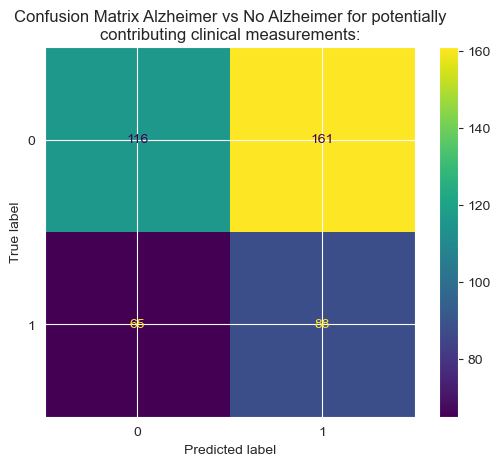

In [47]:
# CELL 19
if __name__ == "__main__":
    print("Logistic Regression Classifier trained with UNDERSAMPLED (balanced) dataset and only features relevant to the second analytical question:")
    logistic_regression(X_under_sampled_features_q2, y_under_sampled, X_val_q2, y_val, X_test_q2, y_test)


Logistic Regression Classifier trained with OVERSAMPLED (balanced) dataset and only features relevant to the second analytical question:

Best parameters found by grid search are: {'C': 1, 'class_weight': None, 'penalty': 'l2', 'solver': 'liblinear'}
Training accuracy: 53.63% 
Validation accuracy: 54.65% 
Accuracy difference (checking for overfitting): -1.03%
Accuracy: 0.521 (+/- 0.026)

Best parameters found by grid search are: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Training accuracy: 53.17% 
Validation accuracy: 56.98% 
Accuracy difference (checking for overfitting): -3.80%
Accuracy: 0.516 (+/- 0.035)

Best parameters found by grid search are: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': np.float64(0.3333333333333333), 'penalty': 'elasticnet', 'solver': 'saga'}
Training accuracy: 53.27% 
Validation accuracy: 56.98% 
Accuracy difference (checking for overfitting): -3.70%
Accuracy: 0.517 (+/- 0.038)
Testing accuracy: 50.47%

Classification

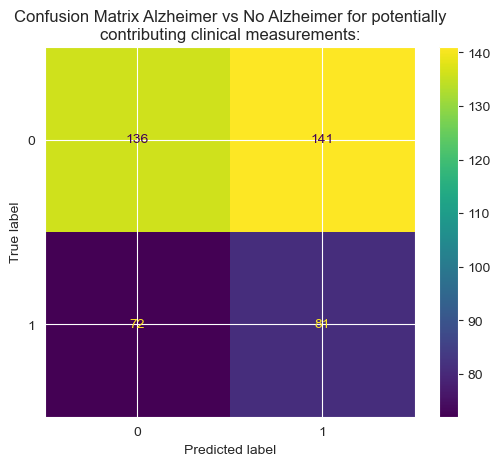

In [48]:
# CELL 20
if __name__ == "__main__":
    print("Logistic Regression Classifier trained with OVERSAMPLED (balanced) dataset and only features relevant to the second analytical question:")
    logistic_regression(X_over_sampled_features_q2, y_over_sampled, X_val_q2, y_val, X_test_q2, y_test)



In [49]:
# CELL 21
'''if __name__ == "__main__":
    print("\n\n\nLogistic Regression Classifier trained with original (unbalanced) dataset and only features relevant to the second analytical question:")
    logistic_regression(X_features_q2, y_train, X_val_q2, y_val, X_test_q2, y_test)'''


'if __name__ == "__main__":\n    print("\n\n\nLogistic Regression Classifier trained with original (unbalanced) dataset and only features relevant to the second analytical question:")\n    logistic_regression(X_features_q2, y_train, X_val_q2, y_val, X_test_q2, y_test)'




Logistic Regression with RFE trained with UNDERSAMPLED (balanced) dataset and only features relevant to the second analytical question:

Best parameters found by grid search are: {'estimator__C': 0.001, 'estimator__class_weight': 'balanced', 'estimator__l1_ratio': np.float64(0.8888888888888888), 'estimator__penalty': 'elasticnet', 'estimator__solver': 'saga'}
Training accuracy: 51.99% 
Validation accuracy: 50.58% 
Accuracy difference (checking for overfitting): 1.40%
Accuracy: 0.501 (+/- 0.019)

Best parameters found by grid search are: {'estimator__C': 0.01, 'estimator__class_weight': 'balanced', 'estimator__penalty': 'l1', 'estimator__solver': 'liblinear'}
Training accuracy: 54.15% 
Validation accuracy: 52.33% 
Accuracy difference (checking for overfitting): 1.83%
Accuracy: 0.489 (+/- 0.071)
Testing accuracy: 50.70%

Classification report for Logistic Regression Classifier with RFE (test dataset):
               precision    recall  f1-score   support

           0       0.66     

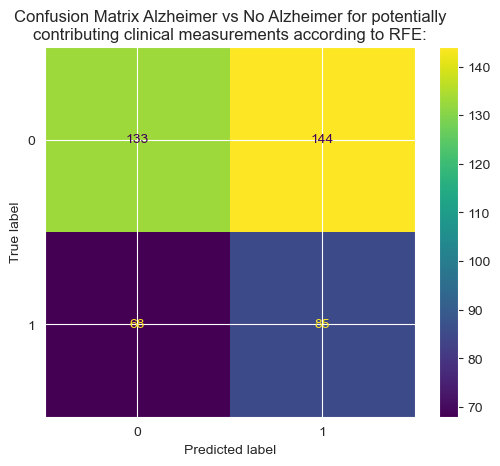

In [50]:
# CELL 22
if __name__ == "__main__":
    print("\n\n\nLogistic Regression with RFE trained with UNDERSAMPLED (balanced) dataset and only features relevant to the second analytical question:")
    rfe_logistic_regression(X_under_sampled_features_q2, y_under_sampled, X_val_q2, y_val, X_test_q2, y_test)





Logistic Regression with RFE trained with OVERSAMPLED (balanced) dataset and only features relevant to the second analytical question:

Best parameters found by grid search are: {'estimator__C': 0.01, 'estimator__class_weight': 'balanced', 'estimator__l1_ratio': np.float64(0.0), 'estimator__penalty': 'elasticnet', 'estimator__solver': 'saga'}
Training accuracy: 52.27% 
Validation accuracy: 57.56% 
Accuracy difference (checking for overfitting): -5.29%
Accuracy: 0.523 (+/- 0.044)

Best parameters found by grid search are: {'estimator__C': 0.01, 'estimator__class_weight': None, 'estimator__penalty': 'l2', 'estimator__solver': 'liblinear'}
Training accuracy: 52.27% 
Validation accuracy: 58.72% 
Accuracy difference (checking for overfitting): -6.46%
Accuracy: 0.525 (+/- 0.044)
Testing accuracy: 51.16%

Classification report for Logistic Regression Classifier with RFE (test dataset):
               precision    recall  f1-score   support

           0       0.66      0.50      0.57      

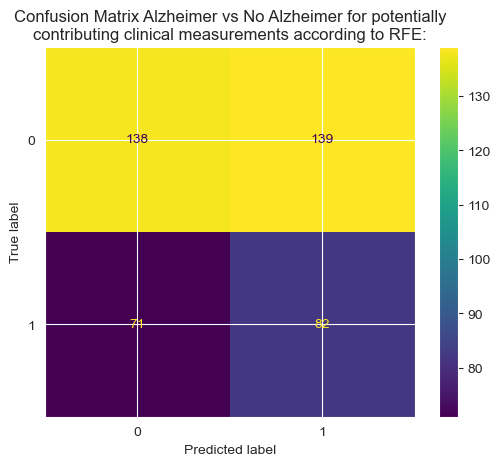

In [51]:
# CELL 23
if __name__ == "__main__":
    print("\n\n\nLogistic Regression with RFE trained with OVERSAMPLED (balanced) dataset and only features relevant to the second analytical question:")
    rfe_logistic_regression(X_over_sampled_features_q2, y_over_sampled, X_val_q2, y_val, X_test_q2, y_test)


In [52]:
# CELL 24
if __name__ == "__main__":
    '''print("\n\n\nLogistic Regression with RFE trained with original (unbalanced) dataset and only features relevant to the second analytical question:")
    rfe_logistic_regression(X_features_q2, y_train, X_val_q2, y_val, X_test_q2, y_test)'''

Modelling >> KMeans Clustering for answering the third analytical question.

In addressing the heterogeneity of Alzheimer’s symptoms and the strain this possess on accurate
diagnosis, we must investigate the relationship between the symptoms we have identified as being
less common in patients with a positive diagnosis and the clinical, environmental and lifestyle
factors most contributing to the development of the disease. This could aid in the diagnosis of
patients with an atypical symptomatic profile. Is an atypical symptomatic profile usually
accompanied by a particular set of clinical, environmental and lifestyle factors?

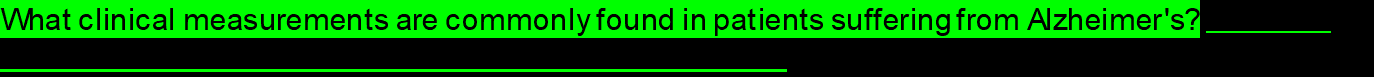
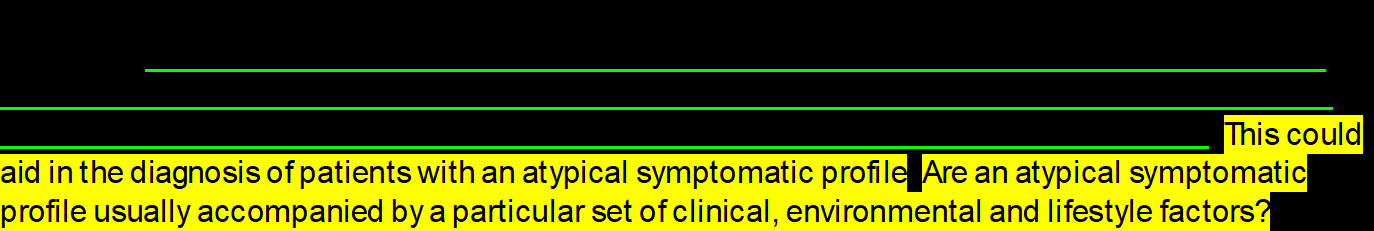
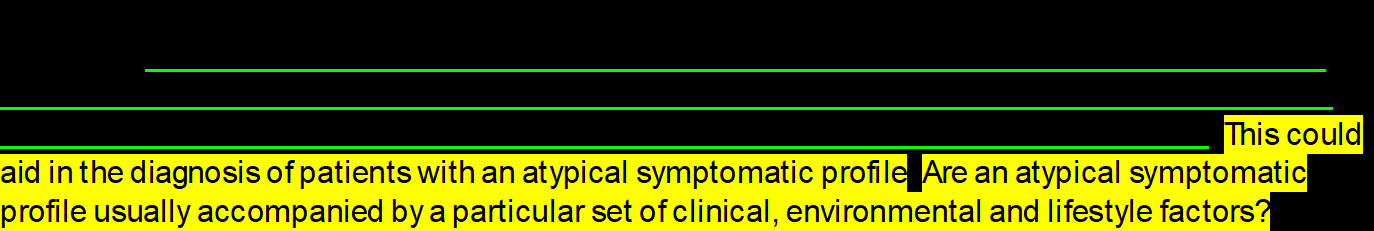

In [53]:
# CELL 25
# CODE KMEANS CLUSTERING FOR QUESTION 3

# To answer this analytical question, we must first determine what comprises an atypical symptomatic profile so that once the clusters have been formed, we can compare the clinical, environmental and lifestyle factors that clump together when symptoms are atypical and when symptoms are typical.

# all of the symptoms are categorical variables, where 0 indicates No and 1 indicates Yes. As such, calculating the sum of 0 and 1 values for each symptom for all positive and negative diagnosis data points will reveal what symptoms are more and less common in patients with the disease

def symptom_prevalence(symptoms, all_positive_cases, all_cases): # no need for target/y_resampled or features/X_features_q3. And, symptoms is X_symptoms_with_diagnosis_q3, all_positive_cases is alzheimers_positive_q3_df and all_cases is alzheimers_df
    positive_count = all_positive_cases.count()['Diagnosis'] #all_positive_cases.count()[0]
    negative_count = (all_cases[all_cases['Diagnosis'] == 0]).count()['Diagnosis'] #(all_cases[all_cases['Diagnosis'] == 0]).count()[0]
    print(f"Positive count: {positive_count}\nNegative count: {negative_count}")

# symptoms is X_symptoms_with_diagnosis_q3, factors is X_factors_identified_with_diagnosis_q3
    symptom_prevalence_positive_df = (symptoms[symptoms['Diagnosis'] == 1].sum(axis=0)/positive_count)*100
    symptom_prevalence_negative_df = (symptoms[symptoms['Diagnosis'] == 0].sum(axis=0)/negative_count)*100
    #most_common_symptoms_positive_and_negative= symptoms['Diagnosis'].sum(axis=0)
    print(f"Most common symptoms in patients with positive diagnosis:\n{symptom_prevalence_positive_df.sort_values(ascending=False)}"
          f"\nPresence of this same symptoms on patients with a negative diagnosis:\n{symptom_prevalence_negative_df.sort_values()}"
          )
    #return symptom_prevalence_positive_df.sort_values(ascending=True) #, symptom_prevalence_negative_df.sort_values(ascending=True)





In [54]:
# CELL 26
def kmeans_clustering(features, feature_to_visualise1 = None, feature_to_visualise2 = None): #(symptoms, factors, features, target):
    # tutorials followed https://www.datacamp.com/tutorial/k-means-clustering-python and https://www.kaggle.com/code/prashant111/k-means-clustering-with-python
    # https://www.datacamp.com/community/tutorials/k-means-clustering-python#gs.123456
    # https://www.kaggle.com/code/prashant111/k-means-clustering-with-python/notebook#Plotting-the-Clusters


    # The dataset being used for this project is labelled, however, for the purpose of this question, we do not need the labels as they do not aid in answering the question.

    # from the results of executing function symptom_prevalence(), it can be clearly observed that, regardless of whether data is resampled or not, the more common symptoms in patients suffering from Alzheimer's, which are also the less commonly found in individuals that do not have the disease, are MemoryComplaints, Forgetfulness and BehavioralProblems.
    # As such, we can consider an atypical asymptomatic profile to be one where the patient, even though diagnosed with the disease, does not suffer from MemoryComplaints, Forgetfulness and BehavioralProblems.


    # According to lecture 8, the next step is to determine the adequate number of clusters using techniques such as the elbow method, silhouette analysis, etc. Code for silhouette analysis adapted from https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html#sphx-glr-auto-examples-cluster-plot-kmeans-silhouette-analysis-py
    range_n_clusters = [2, 3, 4, 5, 6, 7, 8, 9, 10]
    silhouette_avg_dict = {}

    for n_clusters in range_n_clusters:
        # Create a subplot with 1 row and 2 columns
        fig, (ax1, ax2) = plt.subplots(1, 2)
        fig.set_size_inches(18, 7)

        # The 1st subplot is the silhouette plot
        # The silhouette coefficient can range from -1, 1 but in this example all
        # lie within [-0.1, 1]
        ax1.set_xlim([-0.1, 1])
        # The (n_clusters+1)*10 is for inserting blank space between silhouette
        # plots of individual clusters, to demarcate them clearly.
        ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

        # Initialize the clusterer with n_clusters value and a random generator
        # seed of 42 for reproducibility.
        kmeans_model_clusterer = KMeans(n_clusters=n_clusters, random_state=42)
        kmeans_model = kmeans_model_clusterer.fit_predict(features)

        # The silhouette_score gives the average value for all the samples.
        # This gives a perspective into the density and separation of the formed
        # clusters
        silhouette_avg = silhouette_score(features, kmeans_model)
        silhouette_avg_dict[n_clusters] = silhouette_avg
        print(
            "For n_clusters =",
            n_clusters,
            "The average silhouette_score is :",
            silhouette_avg,
        )

        # Compute the silhouette scores for each sample
        sample_silhouette_values = silhouette_samples(features, kmeans_model)

        y_lower = 10
        for i in range(n_clusters):
            # Aggregate the silhouette scores for samples belonging to
            # cluster i, and sort them
            ith_cluster_silhouette_values = sample_silhouette_values[kmeans_model == i]

            ith_cluster_silhouette_values.sort()

            size_cluster_i = ith_cluster_silhouette_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_clusters)
            ax1.fill_betweenx(
                np.arange(y_lower, y_upper),
                0,
                ith_cluster_silhouette_values,
                facecolor=color,
                edgecolor=color,
                alpha=0.7,
            )

            # Label the silhouette plots with their cluster numbers at the middle
            ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

            # Compute the new y_lower for next plot
            y_lower = y_upper + 10  # 10 for the 0 samples

        ax1.set_title("The silhouette plot for the various clusters.")
        ax1.set_xlabel("The silhouette coefficient values")
        ax1.set_ylabel("Cluster label")

        # The vertical line for average silhouette score of all the values
        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

        ax1.set_yticks([])  # Clear the yaxis labels / ticks
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

        # 2nd Plot showing the actual clusters formed
        colors = cm.nipy_spectral(kmeans_model.astype(float) / n_clusters)
        ax2.scatter(features.iloc[:, 0], features.iloc[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k")


        # Labeling the clusters
        centers = kmeans_model_clusterer.cluster_centers_
        # Draw white circles at cluster centers
        ax2.scatter(
            centers[:, 0],
            centers[:, 1],
            marker="o",
            c="white",
            alpha=1,
            s=200,
            edgecolor="k",
        )

        for i, c in enumerate(centers):
            ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

        ax2.set_title("The visualization of the clustered data.")
        ax2.set_xlabel("Feature space for the 1st feature")
        ax2.set_ylabel("Feature space for the 2nd feature")

        plt.suptitle(
            "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
            % n_clusters,
            fontsize=14,
            fontweight="bold",
        )
    plt.show()

    # averaged for an overall assessment (slide 60, lecture 8)
    silhouette_mean = sum(silhouette_avg_dict.values())/len(range_n_clusters)
    print(f"Average silhouette score: {silhouette_mean}")
    for n_clusters in range_n_clusters:
        if silhouette_mean > silhouette_avg_dict.get(n_clusters):
            silhouette_avg_dict.pop(n_clusters)
    print(f"The most optimal number of clusters are: {silhouette_avg_dict}\n")

    # From this, we can see that the closest to optimal number of clusters is 2 and retrain the model using this number.
    kmeans_model = KMeans(n_clusters=2, random_state=42)
    kmeans_model.fit_predict(features)

    clusterLabels = kmeans_model.labels_ # "labels_" as in giving a identificator to each cluster so we are able to say, whatever sample is in cluster labelled/identified by 0, or clustered labelled/identified by 1 (number = number of clusters). This have nothing to do with the bales of the sataset, which have not been used to train, predict or at any point for kmeans_model.

    # Validation using formal methods:
    # In clustering models, we do not test for accuracy, so how do we evaluate the model?
    # Why were this never implemented? All of these metrics are only for comparing assigned labels to ground truth labels, which is not what I need for my project, so I cannot evaluate the performance of kmeans -- it does not seem like sklearn provides functionality for it.


    # After predicting with the retrained model, we can assess the clusters by techniques in slide 56, lecture 8. I.e. interpret the results of the model to answer the analytical question.

    # "Visualize the results on PCA-reduced data. PCA allows to project the data from the original 64-dimensional space into a lower dimensional space. Subsequently, we can use PCA to project into a 2-dimensional space and plot the data and the clusters in this new space.", as per tutorial https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_digits.html , which is from where I adapted the code for PCA:
    pca = PCA(n_components=2)
    features_2d = pca.fit_transform(features)
    # Look at the component loadings -- how much variance each component captures.
    print("The amount of variance explained by each of the selected components:\n", pca.explained_variance_)
    print("Percentage of variance explained by each of the selected components:\n", pca.explained_variance_ratio_)
    # Plot the clusters
    plt.scatter(features_2d[:, 0],features_2d[:, 1], c=clusterLabels, cmap="viridis", s=40)
    plt.show()

    # Assessment of the clusters. "Analyzing the Clusters: Now that we've created our customer segments, let's analyze them to understand what makes each cluster unique. We'll start by examining the average values of numeric variables for each cluster", https://www.dataquest.io/blog/customer-segmentation-using-k-means-clustering/?utm_source=chatgpt.com , which is from where I adapted the following code:
    #numeric_columns = df.select_dtypes(include=np.number).drop(['customer_id', 'CLUSTER'], axis=1).columns


    clusters_df = pd.DataFrame(features, columns=features.columns)
    clusters_df["cluster"] = clusterLabels
    cluster_means_df = clusters_df.groupby("cluster").mean()
    print(f"Mean of each feature in the clusters:\n{cluster_means_df.head(cluster_means_df.shape[0])}")
    #b = pd.DataFrame(cluster_means_df)
    #b.to_excel("mean_of_each_feature_in_clusters.xlsx")
    #print(f"Cluster {i}:\n{cluster_means_df[i]}")

    #The following code was inspired by: https://medium.com/analytics-vidhya/clustering-and-profiling-customers-using-k-means-9afa4277427
    # Add cluster labels
    # done in clusters_df["cluster"] = clusterLabels already


    # Overall level summary
    df_profile_overall = clusters_df.describe().T
    print(f"Overall level summary:\n{df_profile_overall}")

    # using mean; use appropriate summarization (median, count, etc.) for each feature
    df_profile_overall['Overall Dataset'] = df_profile_overall[['mean']]
    df_profile_overall = df_profile_overall[['Overall Dataset']]
    print(f"Summarization (median, count, etc.) for each feature:\n{df_profile_overall}")

    # Cluster level summary
    df_cluster_summary = clusters_df.groupby("cluster").describe().T.reset_index()
    print(f"Cluster level summary:\n{df_cluster_summary}")

    # =========================
    # Overall level summary
    # =========================
    df_profile_overall_v2 = (clusters_df.drop(columns="cluster").agg(["mean"]).T.rename(columns={"mean": "Overall Dataset"}))
    print(f"Overall level summary v2:\n{df_profile_overall_v2}")

    # =========================
    # Cluster-level summary
    # =========================
    df_cluster_summary_v2 = clusters_df.groupby("cluster", as_index=False).mean(numeric_only=True).set_index("cluster").T
    print(f"Cluster-level summary v2:\n{df_cluster_summary_v2}")

    # =========================
    # Join into single profile
    # =========================
    df_profile = df_cluster_summary.join(df_profile_overall)
    print(f"Cluster profile summary:\n{df_profile}")

    # The following code was inspired by https://www.statology.org/performing-cluster-analysis-in-python-a-step-by-step-tutorial/?utm_source=chatgpt.com
    # Visualize the clusters per feature score
    if feature_to_visualise1 is not None and feature_to_visualise2 is not None:
        plt.figure(figsize=(10, 6))
        a = pd.DataFrame(clusters_df[feature_to_visualise1])
        b = pd.DataFrame(clusters_df[feature_to_visualise2])
        clusters_df_pca = pd.concat([a, b], axis=1)
        pca = PCA(n_components=2)
        f = pca.fit_transform(clusters_df_pca)
        plt.scatter(f[:, 0], f[:, 1], c=clusterLabels, cmap="viridis", s=40)
        plt.xlabel(feature_to_visualise1)
        plt.ylabel(feature_to_visualise2)
        plt.show()




In [55]:
# CELL 27
if __name__ == "__main__":
    print(f"\n\n\nSymptom prevalence (no resampling):\n")
    symptom_prevalence(X_symptoms_with_diagnosis_q3, alzheimers_positive_q3_df, alzheimers_df)





Symptom prevalence (no resampling):

Positive count: 760
Negative count: 1389
Most common symptoms in patients with positive diagnosis:
Diagnosis                    100.000000
MemoryComplaints              37.631579
Forgetfulness                 30.131579
BehavioralProblems            26.710526
Confusion                     19.473684
DifficultyCompletingTasks     16.315789
Disorientation                14.605263
PersonalityChanges            14.078947
dtype: float64
Presence of this same symptoms on patients with a negative diagnosis:
Diagnosis                     0.000000
BehavioralProblems            9.647228
MemoryComplaints             11.591073
PersonalityChanges           15.622750
DifficultyCompletingTasks    15.622750
Disorientation               16.486681
Confusion                    21.094312
Forgetfulness                30.165587
dtype: float64





K-Means clustering trained with original (unbalanced) dataset and only features relevant to the third analytical question:
For n_clusters = 2 The average silhouette_score is : 0.3942783256044059
For n_clusters = 3 The average silhouette_score is : 0.25968497310084715
For n_clusters = 4 The average silhouette_score is : 0.2115972785676574
For n_clusters = 5 The average silhouette_score is : 0.20062973828160655
For n_clusters = 6 The average silhouette_score is : 0.1758300568199691
For n_clusters = 7 The average silhouette_score is : 0.1718411640953019
For n_clusters = 8 The average silhouette_score is : 0.1713736040674708
For n_clusters = 9 The average silhouette_score is : 0.16949469744378834
For n_clusters = 10 The average silhouette_score is : 0.18042319500946435


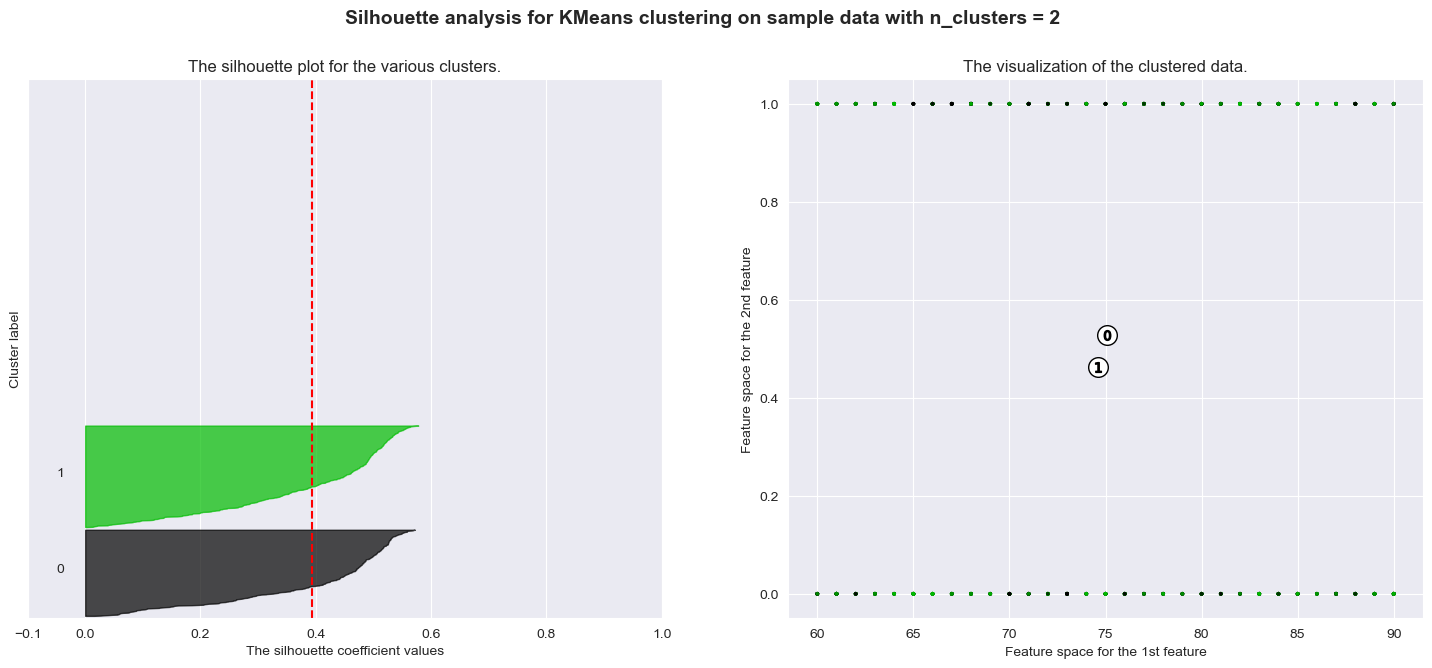

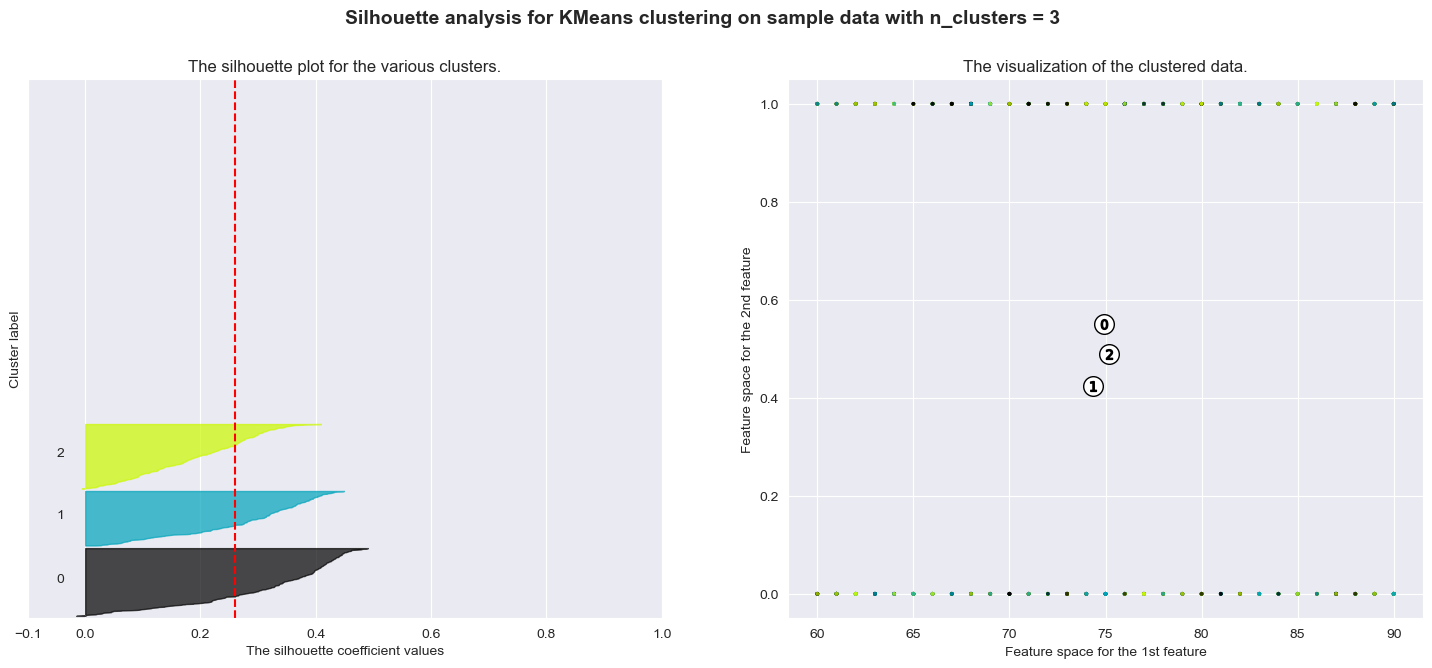

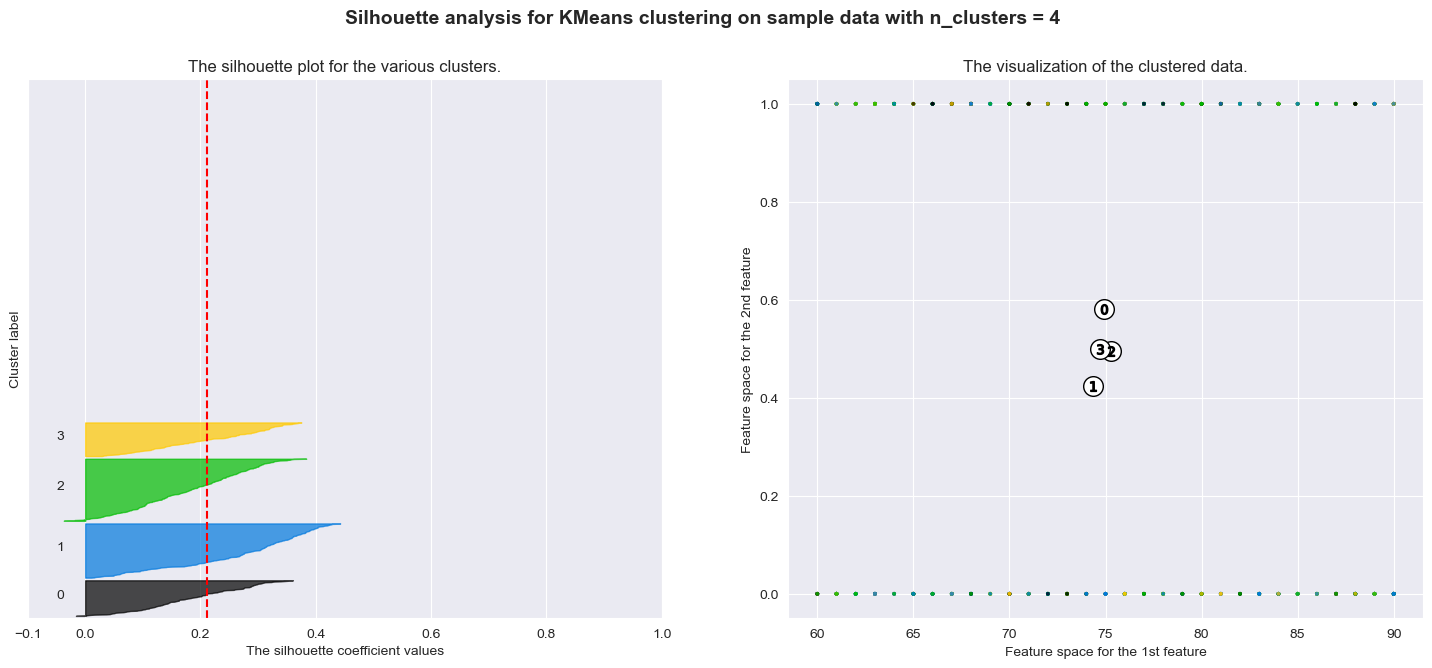

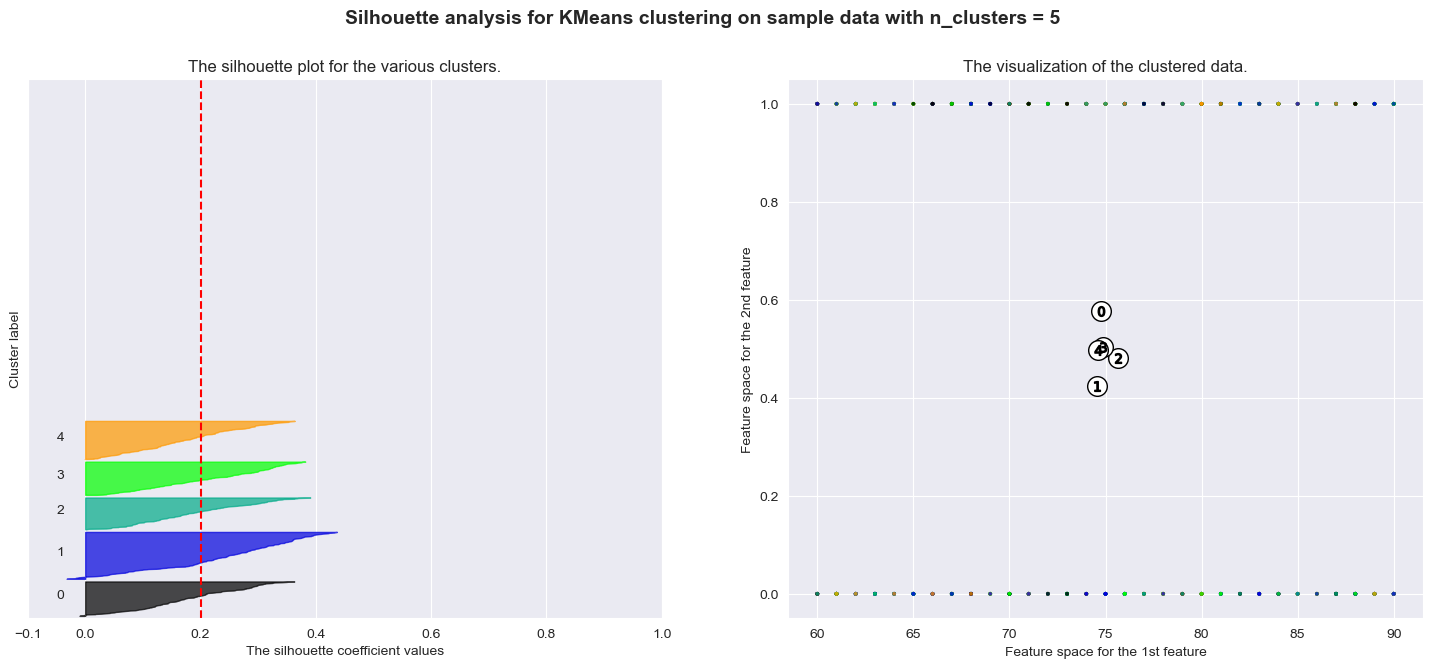

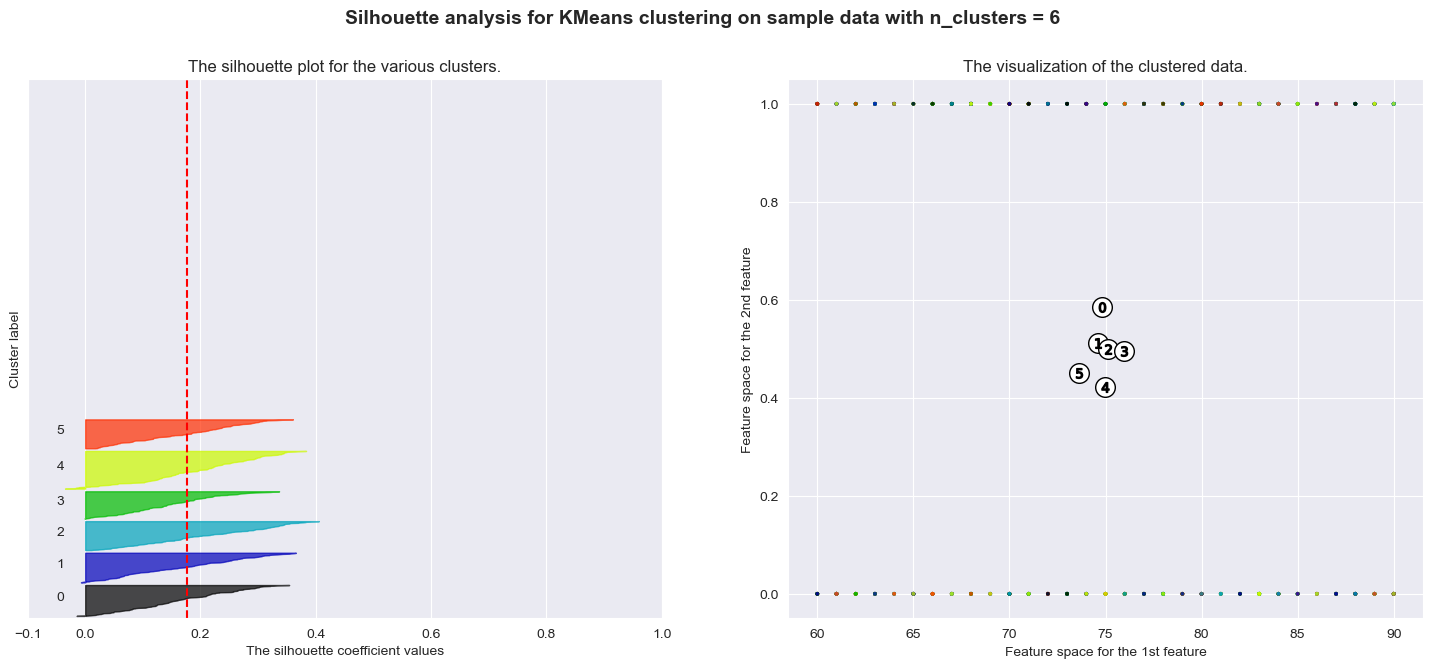

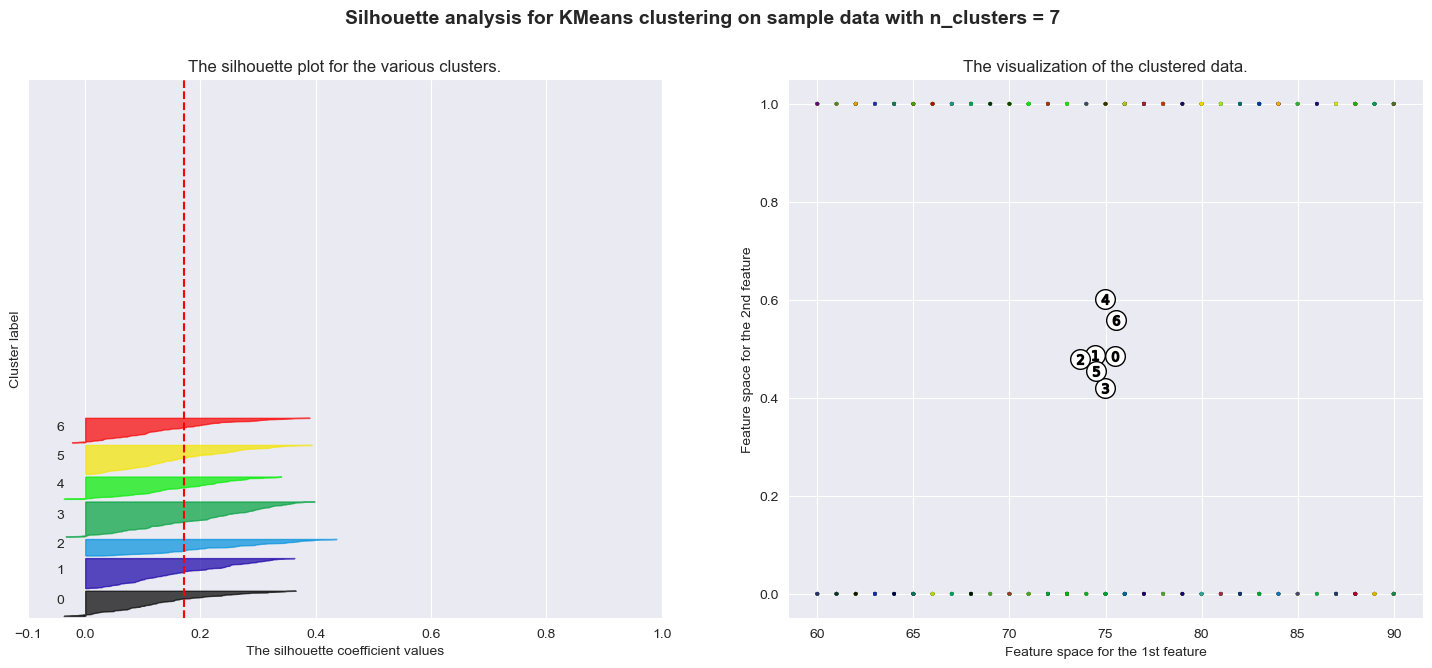

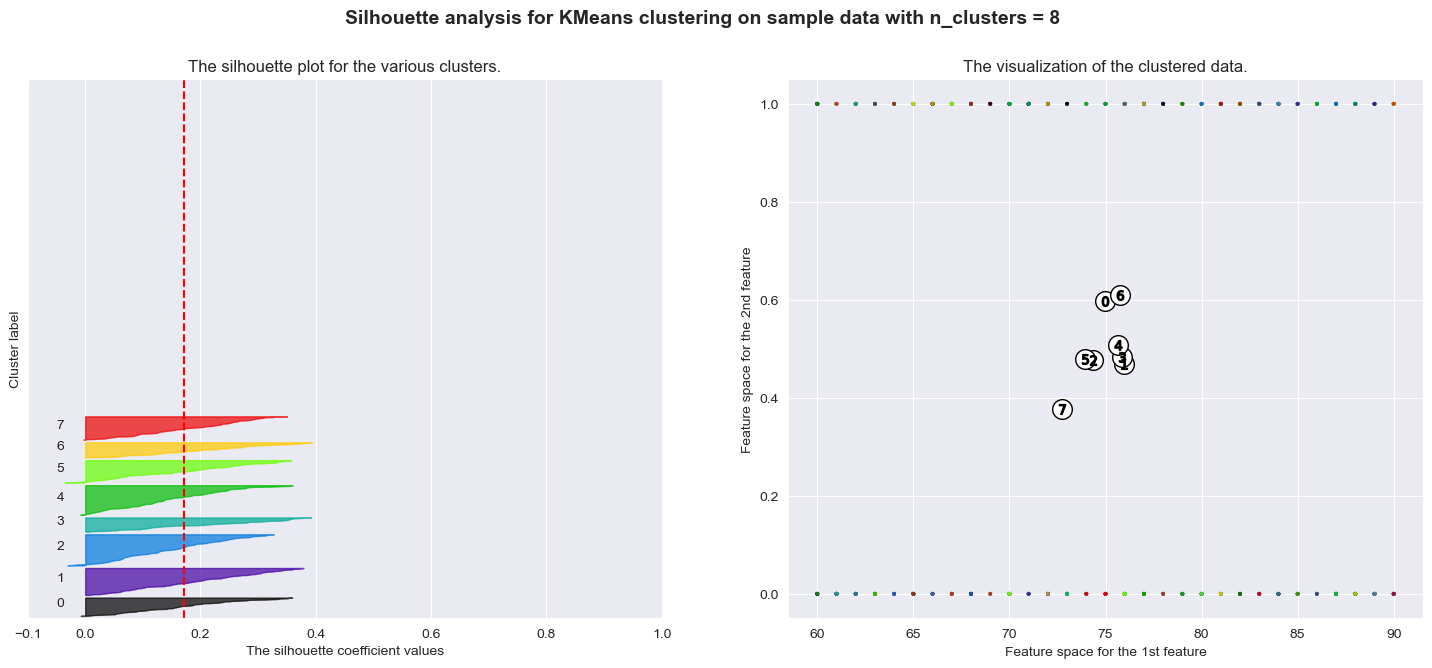

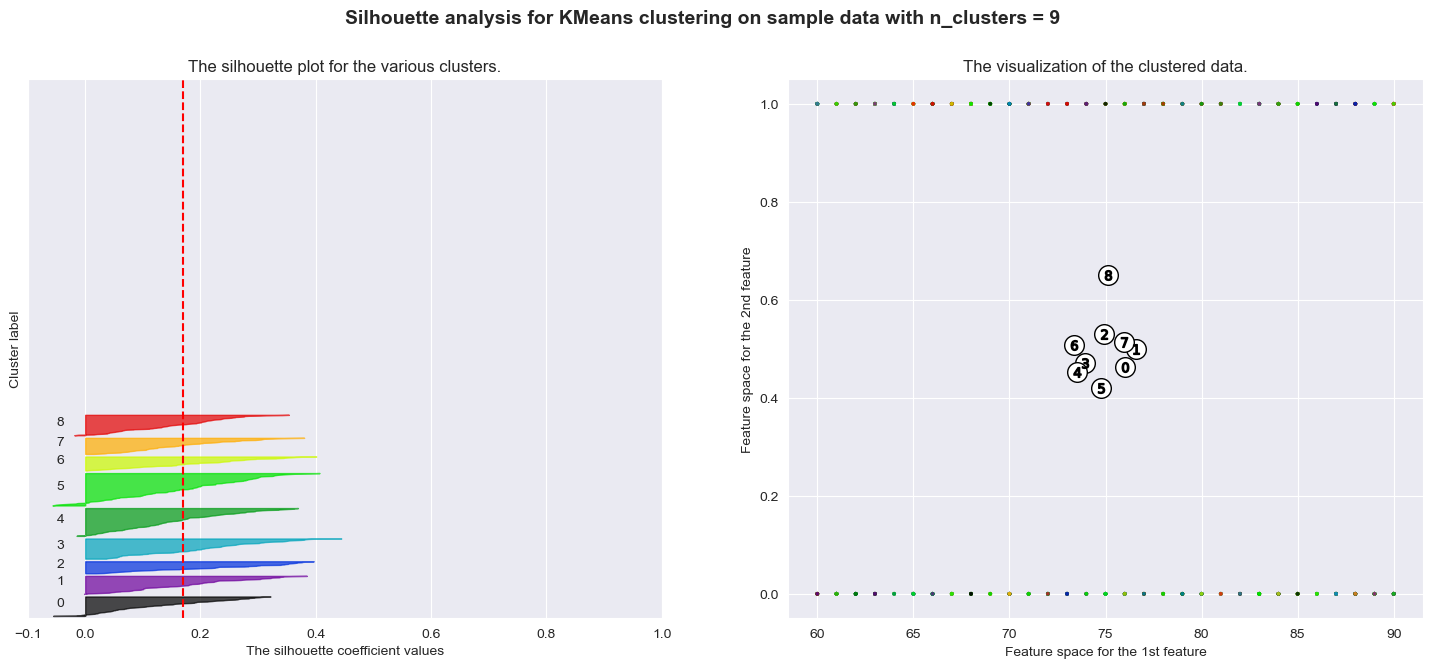

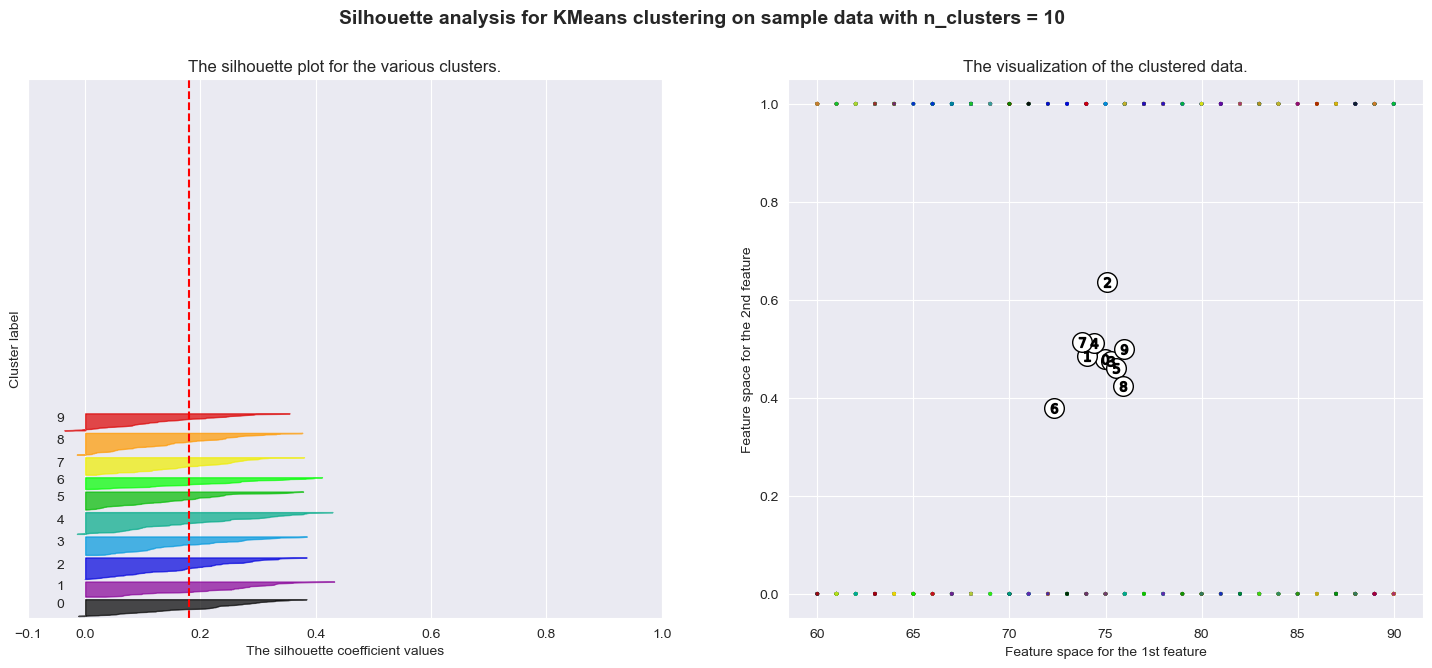

Average silhouette score: 0.21501700366561238
The most optimal number of clusters are: {2: 0.3942783256044059, 3: 0.25968497310084715}

The amount of variance explained by each of the selected components:
 [10433.55363258  1873.83780406]
Percentage of variance explained by each of the selected components:
 [0.65450132 0.11754665]


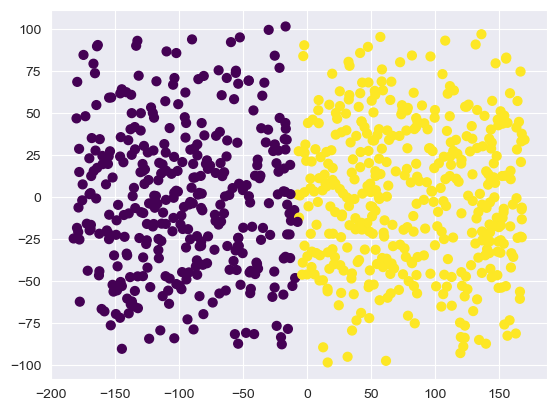

Mean of each feature in the clusters:
               Age    Gender  Ethnicity  EducationLevel        BMI   Smoking  \
cluster                                                                        
0        75.094556  0.527221   0.667622        1.283668  28.194071  0.286533   
1        74.627737  0.462287   0.686131        1.189781  27.673720  0.284672   

         AlcoholConsumption  PhysicalActivity  DietQuality  SleepQuality  ...  \
cluster                                                                   ...   
0                 10.014397          4.897441     4.915640      6.896188  ...   
1                  9.951081          4.981983     5.120786      6.933363  ...   

              MMSE  FunctionalAssessment  MemoryComplaints  \
cluster                                                      
0        11.549984              3.808676          0.383954   
1        12.372251              3.521511          0.369830   

         BehavioralProblems       ADL  Confusion  Disorientation  \

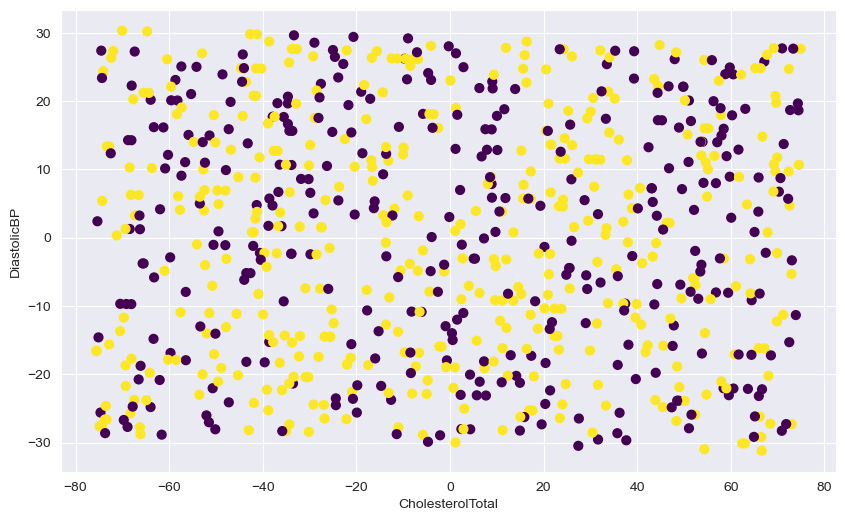

In [56]:
# CELL 28
if __name__ == "__main__":
    print("\n\n\nK-Means clustering trained with original (unbalanced) dataset and only features relevant to the third analytical question:")
    kmeans_clustering(X_features_q3, "CholesterolTotal", "DiastolicBP")
